<a href="https://colab.research.google.com/github/owlmt/QML/blob/main/01_Network_Intrusion_Detection/VQRL_IntrusionDetection_Kerkatou2026.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Variational quantum reinforcement learning for intrusion detection: Kerkatou et al. (2026) step by step

This notebook re-implements, runs and checks the method of

> Raid Anis Kerkatou, Hacene Belhadef, Aicha Eutamene and Svetlana Petrova Stefanova, "Embedding-Dependent Performance of
> Variational Quantum Reinforcement Learning for Intrusion Detection Under Dimensionality Constraints",
> *Electronics* 15(13), 2853, MDPI, 2026. DOI 10.3390/electronics15132853

The authors publish their code (<https://github.com/raidanis/QRL_IDS>, a collection of Colab notebooks). This notebook is written
against **commit `f7b8a007e8630ca1ae4983dd78e3a7c1990dc15e`** of that repository: the streaming environment, the reward, the
REINFORCE loop, the classical policy and the hybrid quantum policy (`IQPEmbedding` + `StronglyEntanglingLayers`) are taken from its
CICIDS2017-DDoS notebooks and checked against the paper's Table 1 and Algorithm 1. Where the repository and the paper disagree,
the notebook follows the paper's text (for example, the paper fits the scaler and the PCA on the training split only; the repository
fits them on all data) and says so.

**What the notebook does.** It downloads the CIC-IDS2017 Friday-afternoon DDoS capture (Normal vs DDoS, the paper's only dataset),
cleans it, draws a class-balanced sample of 25,000 flows, splits it 80 : 20, standardises and PCA-compresses it (fitted on the training
split), and then trains two reinforcement-learning agents with REINFORCE: a **classical** MLP policy and a **hybrid quantum** policy
whose middle layer is an IQP-embedded, strongly-entangling variational circuit simulated on PennyLane's statevector backend. It
reproduces the paper's analyses in turn: the best-configuration comparison (Table 2, Figures 3-6), the PCA sweep (Tables 3 and 6),
repeated runs with mean and standard deviation, ROC-AUC (Tables 4 and 5, Figures 7-8), the reward-sensitivity sweep (Table 7), an
ablation of the embedding (Figure 11, which the paper only shows qualitatively), and the five supervised baselines (Table 8,
Figures 12-14). The last section puts every checkable number of the paper next to ours with a verdict per claim.

**How to run it.** Open in Colab (badge above), choose a CPU runtime and use *Runtime -> Run all*. The first cell installs a pinned
PennyLane; if Colab asks to restart the session, restart and run all again. No GPU, no quantum-cloud account and no Hugging Face
account are needed for this dataset (the dataset is public; if you ever hit a rate limit, add your own token as the Colab secret
`HF_TOKEN`, Settings -> Secrets).

**Runtime.** `FAST_MODE = True` (5,000 flows, 150 training episodes, PCA 4/6/8, 2 seeds, a 4-point reward grid) is a class demo of a few
minutes. `FAST_MODE = False` follows the paper's budget: 25,000 flows, **1,000 episodes of 200 steps**, PCA 2/4/6/8/10, 5 seeds, the
paper's 16-point reward grid. The paper's own run took about 77 minutes per quantum training run (Table 4); this notebook trains the
same circuit through an exact batched statevector simulator that is checked against PennyLane (the circuit-drawing section further down), which is why it is much
faster. The run times of the committed outputs are stated in the last section.

**What you get at the end.** A table of the paper's claims next to this notebook's numbers with a verdict for each ("reproduced",
"not reached", "exceeded", "cannot be checked"), the training curves, confusion matrices and ROC curves, the drawn circuits,
and a critical reading of what the paper does and does not show.

## The paper in one page

**Problem.** Network intrusion detection where a missed attack (false negative) costs far more than a false alarm. The paper treats
detection as a *reinforcement-learning* problem only to put that asymmetry into the reward; it says plainly that the flows are
independent, that there are no delayed rewards and that no sequential structure is exploited.

**Decision.** At every step the agent sees one flow, chooses `0` (normal) or `1` (attack) and receives the reward of Eq. (6):
**+2** for a true positive or true negative, **-2** for a false negative, **-0.5** for a false positive.

**Method.** Two policies trained with REINFORCE (Eq. 8) under identical conditions. *Classical RL*: an MLP with ReLU layers and a
softmax. *VQRL-IQP*: a hybrid network, linear layer to `n` features -> **IQP embedding** (Eq. 9) -> variational circuit of `L = 2`
`StronglyEntanglingLayers` (Table 1: `3 x n x L` trainable angles, full all-to-all entanglement topology, exact statevector simulation,
PennyLane 0.38 `default.qubit`) -> Pauli-Z expectation values (Eq. 11) -> classical layers -> softmax.

**Data.** CIC-IDS2017, binary Normal vs DDoS from a single day (Friday afternoon). A balanced subset (the text says 45,000 flows,
the test set of Fig. 12 has 2,514 attack + 2,486 benign flows = 5,000 = 20 % of **25,000**, which is also the number in the authors'
code). Order of operations: stratified 80 : 20 split -> `StandardScaler` on the training part -> PCA to `n in {2, 4, 6, 8, 10}`
qubits on the training part.

**Claims the notebook can test.**

| Where | Claim |
|---|---|
| Table 2 (best single run) | Classical RL, PCA 6: acc 0.9602, prec 0.9928, recall 0.9275, F1 0.9590. VQRL-IQP, PCA 8: acc 0.9582, prec 0.9228, recall 0.9988, F1 0.9593 |
| Table 3 (best single run per PCA) | five PCA sizes, both models; VQRL-IQP FNR 0.0012 and FPR 0.0812 at PCA 8 (Fig. 6) |
| Table 4 (repeated runs) | Classical: acc 0.9198 +/- 0.0783, recall 0.8470, FPR 0.0070. VQRL-IQP: acc 0.7820 +/- 0.0143, recall 0.8084, FPR 0.2445. Training time 63 s vs 4615 s |
| Table 5 | Mean ROC-AUC: classical 0.9910, VQRL-IQP 0.8740 |
| Table 6 (fixed budget) | cumulative PCA variance 0.3838 / 0.5751 / 0.6709 / 0.7383 / 0.7946; VQRL-IQP collapses to "predict attack for everything" for PCA >= 6 |
| Table 7 (reward sweep) | 16 (FN, FP) penalty pairs; VQRL-IQP non-degenerate in only 2, classical RL in 6 |
| Table 8 (supervised baselines) | RF 99.78 %, XGBoost 99.74 %, SVM-RBF 99.10 %, MLP 99.66 %, cost-sensitive RF 99.80 % accuracy |
| Text | VQRL-IQP has a lower FNR but a higher FPR than classical RL; classical RL has slightly higher accuracy; no quantum advantage is claimed |

The headline accuracy range of the task description (99.1-99.8 %) is the supervised baselines of Table 8, not the quantum agent.
The paper's abstract and Limitations list NSL-KDD, UNSW-NB15 and CIC-IoT2023 as *future work*; the paper reports **no results on them**,
so this notebook uses CIC-IDS2017 only.

## What follows the paper and what had to be chosen

| Item | Paper | This notebook |
|---|---|---|
| Dataset | CIC-IDS2017, Normal vs DDoS (single day) | Friday-WorkingHours-Afternoon-DDos CSV from the Hugging Face mirror `c01dsnap/CIC-IDS2017` (the file the authors' code loads) |
| Cleaning | duplicates and corrupt rows removed | duplicates dropped, +/-inf -> NaN, NaN -> training median (the code fills two columns with the full-data median; here: all columns, training median), constant columns dropped |
| Sample | "45,000" in the text, 5,000 test flows in Fig. 12 | 12,500 + 12,500 flows drawn **without replacement** (`# CHOICE`; the authors' code samples benign flows with replacement, which puts duplicate rows on both sides of the split) |
| Split / scaling / PCA | 80 : 20 stratified; scaler and PCA fitted on the training split | same. The repository fits them (and SMOTE) on all data before splitting; that leaks test information and is not copied |
| PCA | one fit per size | one `PCA(10)` fit on the training split, the first `n` scores used for size `n` (identical to separate fits; `# CHOICE` for speed) |
| Environment | streaming, 1 flow per step | episodes = 200 consecutive flows of a fixed random permutation, random start (authors' `IDSStreamEnv`) |
| Reward | +2 / +2 / -2 / -0.5 | same (Eq. 6) |
| Algorithm | REINFORCE, Adam 1e-3, 1000 episodes, `gamma` 0.99 | same; returns normalised per episode as in the code (`# CHOICE`: not stated in the paper) |
| Classical policy | MLP, ReLU, softmax | 64-64 ReLU MLP (authors' code) |
| Quantum policy | linear -> IQP -> 2 x StronglyEntanglingLayers -> Z expvals -> classical layers | `Linear(n,n)` + tanh -> `IQPEmbedding` -> `StronglyEntanglingLayers(2)` -> `Linear(n,32)` + tanh -> `Linear(32,2)` (authors' code) |
| Gradient method | parameter-shift (Table 1) | the authors' code uses `diff_method="backprop"` (parameter-shift is commented out); both are exact on a statevector simulator. This notebook uses autograd and **checks it against parameter-shift** (the circuit-drawing section further down) |
| Simulator | PennyLane 0.38 `default.qubit` | PennyLane 0.45.1 for drawing and verification; training uses a batched exact statevector simulator of the same circuit (`# CHOICE`, speed), validated to 1e-12 against the QNode |
| Seeds | "five independent runs" (Table 4), three AUC runs (Table 5) | `SEED = 42`, runs use seeds 42 + k |
| Table 3 "individually tuned" runs | per-PCA tuning not described | not reproducible; we report the mean +/- std over seeds and, in addition, the best seed chosen on the **test** set the way the paper does (optimistic, labelled as such) |
| Table 7 base rewards | only FN and FP varied | TP = TN = +2 held fixed (`# CHOICE`) and the sweep run at PCA 8 (`# CHOICE`) |
| Ablation (Fig. 11) | qualitative, no numbers | we compute numbers for IQP, `AngleEmbedding` (in the authors' repository), a hybrid without any quantum layer, and the classical MLP |
| Supervised baselines (Table 8) | RF, XGBoost, SVM-RBF, MLP, cost-sensitive RF; settings not given | scikit-learn / XGBoost defaults on all standardised features; cost-sensitive RF = RF with class weights 1 : 4 (`# CHOICE`, the 2 : 0.5 reward ratio) |
| Training time | 63 s vs 4615 s, 1000 episodes | measured, but **not comparable** (different simulator, hardware and per-step vs batched forward pass) |

## 0. Setup

In [1]:
# Versions tested with this notebook (October 2026). Colab already ships numpy, pandas, scikit-learn, matplotlib, torch, xgboost.
# The pip line runs on Colab (or wherever PennyLane is missing); a prepared local environment is left untouched.
import importlib.util
IN_COLAB = importlib.util.find_spec("google.colab") is not None
missing = [m for m in ("pennylane", "torch", "xgboost", "huggingface_hub", "seaborn") if importlib.util.find_spec(m) is None]
if IN_COLAB or missing:
    %pip install -q "pennylane==0.45.1" xgboost huggingface_hub seaborn
    if importlib.util.find_spec("torch") is None:
        %pip install -q torch --index-url https://download.pytorch.org/whl/cpu
    print("Packages installed. If Colab asks you to restart the session, do so and run all cells again.")
else:
    print("All packages already present; skipping pip install.")

All packages already present; skipping pip install.


In [2]:
# ---------------- configuration ----------------
FAST_MODE = False          # True: class demo (a few minutes). False: the paper's budget (25,000 flows, 1,000 episodes, 5 seeds, 16 reward pairs).
SEED = 42                  # CHOICE: the paper gives no seed

# --- data (paper: CIC-IDS2017, Normal vs DDoS; 25,000-flow balanced subset, 80:20 stratified split) ---
HF_REPO = "c01dsnap/CIC-IDS2017"
HF_FILE = "Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv"
LOCAL_CSV = None           # set to the path of an uploaded copy of that CSV to skip the download
DATA_DIR = "data"
TEST_SIZE = 0.20

# --- RL environment and REINFORCE (authors' code, commit f7b8a00) ---
EPISODE_LENGTH = 200       # flows per episode
GAMMA = 0.99
LR = 1e-3                  # Adam; paper Table 1: alpha = 0.001, beta1 = 0.9, beta2 = 0.999
N_LAYERS = 2               # StronglyEntanglingLayers, L = 2 (Table 1)
REWARD = (2.0, 2.0, -2.0, -0.5)   # (TP, TN, FN, FP) = Eq. (6)

# --- budgets that differ between the class demo and the full run ---
if FAST_MODE:
    N_PER_CLASS = 2500             # 5,000 flows in total
    EPISODES    = 150              # paper: 1000
    N_SEEDS     = 2                # paper: 5
    N_SEEDS_BY_PCA = {4: 2, 6: 2, 8: 2}
    PCA_LIST    = [4, 6, 8]        # paper: 2, 4, 6, 8, 10
    FN_GRID     = [-1.0, -2.0]     # paper: -1, -2, -3, -4
    FP_GRID     = [-0.5, -1.0]     # paper: -0.5, -1, -1.5, -2
    ABL_SEEDS   = 1
    SMOOTH      = 10
else:
    N_PER_CLASS = 12500            # 25,000 flows in total (test set 5,000, as in the paper's Fig. 12)
    EPISODES    = 1000
    N_SEEDS     = 5
    N_SEEDS_BY_PCA = {2: 5, 4: 5, 6: 5, 8: 5, 10: 3}   # CHOICE: PCA 10 (1,024-dim state) is 5x dearer, 3 seeds only
    PCA_LIST    = [2, 4, 6, 8, 10]
    FN_GRID     = [-1.0, -2.0, -3.0, -4.0]
    FP_GRID     = [-0.5, -1.0, -1.5, -2.0]
    ABL_SEEDS   = 3
    SMOOTH      = 50
PCA_CLASSICAL_BEST = 6     # Table 2: best classical RL configuration
PCA_QUANTUM_BEST   = 8     # Table 2: best VQRL-IQP configuration
REWARD_PCA         = 8     # CHOICE: PCA size used for the reward sweep (paper does not say)
USE_PENNYLANE_LAYER = False    # True: train with the authors' PennyLane TorchLayer (about 100x slower); False: exact batched simulator, verified in the Quantum Circuit Architecture section
AUTHORS_COMMIT = "f7b8a007e8630ca1ae4983dd78e3a7c1990dc15e"   # github.com/raidanis/QRL_IDS

In [3]:
import os, time, warnings, json, io, string
T_START = time.time()
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

warnings.filterwarnings("ignore", category=DeprecationWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

import torch, torch.nn as nn
import pennylane as qml
import sklearn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import confusion_matrix, roc_auc_score, roc_curve

# Hugging Face token (only needed if a dataset is gated or you hit a rate limit; this one is public)
HF_TOKEN = os.environ.get("HF_TOKEN")
if HF_TOKEN is None:
    try:
        from google.colab import userdata          # Colab: Settings > Secrets > HF_TOKEN
        HF_TOKEN = userdata.get("HF_TOKEN")
    except Exception:
        HF_TOKEN = None

# seeds everywhere
np.random.seed(SEED); torch.manual_seed(SEED)
rng = np.random.default_rng(SEED)
torch.set_num_threads(1)     # CHOICE: the tensors are tiny (200 x 2^n); one thread is fastest, also on a busy shared CPU
os.makedirs(DATA_DIR, exist_ok=True)
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 40)
sns.set_theme(style="whitegrid")
print("pennylane", qml.__version__, "| torch", torch.__version__, "| numpy", np.__version__, "| pandas", pd.__version__,
      "| scikit-learn", sklearn.__version__)
print("FAST_MODE =", FAST_MODE, "| flows:", 2 * N_PER_CLASS, "| episodes:", EPISODES, "| seeds:", N_SEEDS, "| PCA sizes:", PCA_LIST)

pennylane 0.45.1 | torch 2.14.1+cpu | numpy 2.5.4 | pandas 3.0.6 | scikit-learn 1.9.1
FAST_MODE = False | flows: 25000 | episodes: 1000 | seeds: 5 | PCA sizes: [2, 4, 6, 8, 10]


## 1. The CIC-IDS2017 Friday-afternoon DDoS capture

CIC-IDS2017 (Sharafaldin et al., 2018) is five days of labelled flow records produced by CICFlowMeter from a lab network. On Friday
afternoon the attacker ran a DDoS (LOIT) attack; the capture therefore contains only two labels, `BENIGN` and `DDoS`, which is exactly
the paper's binary task. The file has 78 numeric flow features plus the label (the "Flow ID", IPs and timestamps are not in this
CSV version). The cell downloads the file from the public Hugging Face mirror (77 MB, cached in `DATA_DIR`).

The authors' cleaning is reproduced in the order of their notebook: strip the column names, drop duplicate rows, turn +/-infinity into
missing values, drop columns with a single value. The only change is that missing values are filled after the split, with the
**training** median.

In [4]:
def get_csv():
    if LOCAL_CSV and os.path.exists(LOCAL_CSV):
        return LOCAL_CSV
    path = os.path.join(DATA_DIR, HF_FILE)
    if os.path.exists(path):
        print("using cached", path); return path
    from huggingface_hub import hf_hub_download
    for tok in (HF_TOKEN, None):
        try:
            p = hf_hub_download(HF_REPO, HF_FILE, repo_type="dataset", local_dir=DATA_DIR, token=tok)
            print("downloaded", HF_FILE, "from", HF_REPO, "->", p); return p
        except Exception as e:
            print("download attempt failed:", type(e).__name__, str(e)[:120])
    raise RuntimeError("Could not download the CSV. Download %s from the Hugging Face dataset %s by hand and set LOCAL_CSV." % (HF_FILE, HF_REPO))

t0 = time.time()
raw = pd.read_csv(get_csv(), encoding="latin1")
raw.columns = raw.columns.str.strip()
print("raw file:", raw.shape, f"({time.time()-t0:.1f}s)")
print("raw label counts:", raw["Label"].value_counts().to_dict())
n_dup = int(raw.duplicated().sum())
data = raw.drop_duplicates().replace([np.inf, -np.inf], np.nan)
print(f"duplicates dropped: {n_dup} | cells that are NaN/inf after cleaning: {int(data.drop(columns='Label').isna().sum().sum())}")
y_all = (data["Label"] != "BENIGN").astype(int).to_numpy()        # 0 = normal, 1 = attack
X_all = data.drop(columns=["Label"])
const_cols = [c for c in X_all.columns if X_all[c].nunique() <= 1]
X_all = X_all.drop(columns=const_cols)
print("constant columns dropped:", const_cols)
print("clean table:", X_all.shape, "| BENIGN:", int((y_all == 0).sum()), "| DDoS:", int((y_all == 1).sum()))

using cached data\Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv


raw file: (225745, 79) (10.7s)
raw label counts: {'DDoS': 128027, 'BENIGN': 97718}


duplicates dropped: 2633 | cells that are NaN/inf after cleaning: 60


constant columns dropped: ['Bwd PSH Flags', 'Fwd URG Flags', 'Bwd URG Flags', 'CWE Flag Count', 'Fwd Avg Bytes/Bulk', 'Fwd Avg Packets/Bulk', 'Fwd Avg Bulk Rate', 'Bwd Avg Bytes/Bulk', 'Bwd Avg Packets/Bulk', 'Bwd Avg Bulk Rate']
clean table: (223112, 68) | BENIGN: 95096 | DDoS: 128016


## 2. Balanced sample, 80 : 20 split, standardisation and PCA (training split only)

The paper's order is: stratified 80 : 20 split -> `StandardScaler` fitted on the training part -> PCA fitted on the training part ->
the same transforms applied to the test part. The balanced subset is drawn first here (equal numbers of normal and DDoS flows, drawn
without replacement), because the 25,000-flow size is fixed by the paper's test set; the split, the median imputation, the scaler and
the PCA are then all fitted on the training rows only. The classical RL agent and the quantum agent receive exactly the same PCA
scores.

In [5]:
idx0 = np.where(y_all == 0)[0]; idx1 = np.where(y_all == 1)[0]
pick = np.concatenate([rng.choice(idx0, N_PER_CLASS, replace=False), rng.choice(idx1, N_PER_CLASS, replace=False)])   # CHOICE: without replacement
X_s, y_s = X_all.iloc[pick].reset_index(drop=True), y_all[pick]
X_tr_raw, X_te_raw, y_train, y_test = train_test_split(X_s, y_s, test_size=TEST_SIZE, random_state=SEED, stratify=y_s)
feature_names = list(X_s.columns)

med = X_tr_raw.median()                                   # training medians
X_tr_raw = X_tr_raw.fillna(med); X_te_raw = X_te_raw.fillna(med)
scaler = StandardScaler().fit(X_tr_raw)                   # fitted on the training split only
Z_tr, Z_te = scaler.transform(X_tr_raw), scaler.transform(X_te_raw)
MAX_PCA = max(PCA_LIST)
pca = PCA(n_components=MAX_PCA, random_state=SEED).fit(Z_tr)    # CHOICE: one fit, first n scores for size n
P_tr, P_te = pca.transform(Z_tr).astype(np.float32), pca.transform(Z_te).astype(np.float32)
cumvar = pca.explained_variance_ratio_.cumsum()
print(f"train {P_tr.shape}, test {P_te.shape} | train classes {np.bincount(y_train).tolist()} | test classes {np.bincount(y_test).tolist()}")
print("cumulative explained variance:", {n: round(float(cumvar[n-1]), 4) for n in PCA_LIST})
print("paper Table 6 (VarExp)       :", {2: 0.3838, 4: 0.5751, 6: 0.6709, 8: 0.7383, 10: 0.7946})

train (20000, 10), test (5000, 10) | train classes [10000, 10000] | test classes [2500, 2500]
cumulative explained variance: {2: 0.3633, 4: 0.5806, 6: 0.6699, 8: 0.741, 10: 0.7979}
paper Table 6 (VarExp)       : {2: 0.3838, 4: 0.5751, 6: 0.6709, 8: 0.7383, 10: 0.7946}


## Dataset Exploration and Visualisation

Before any model is trained, the real data. The cells below print the dimensions, the feature names and the original labels with their
counts, plot the class distribution of the raw file and of the balanced sample, and draw a 2-D scatter in which every point is one real
flow of the training split coloured by its ground-truth label: first the raw PCA coordinates (fitted on the training split), then the
same two coordinates rescaled to $[0, \pi]$, the angle range a rotation-encoded circuit would see. (The authors' hybrid policy does not use
this rescaling: a trainable `Linear` + `tanh` layer turns the PCA scores into the angles of the IQP circuit. The $[0,\pi]$ panel is
therefore the *input geometry* only; the angles the trained circuit really receives are plotted in section 5.) The Friday-afternoon file
has only two labels, so there is no multi-class attack family to colour by.

dataset: CIC-IDS2017, Friday-WorkingHours-Afternoon-DDos (Hugging Face mirror c01dsnap/CIC-IDS2017)
raw shape: (225745, 79) | after cleaning: (223112, 68) (+ label) | balanced sample: (25000, 68)

feature names (68):
Destination Port, Flow Duration, Total Fwd Packets, Total Backward Packets, Total Length of Fwd Packets, Total Length of Bwd Packets, Fwd Packet Length Max, Fwd Packet Length Min, Fwd Packet Length Mean, Fwd Packet Length Std, Bwd Packet Length Max, Bwd Packet Length Min, Bwd Packet Length Mean, Bwd Packet Length Std, Flow Bytes/s, Flow Packets/s, Flow IAT Mean, Flow IAT Std, Flow IAT Max, Flow IAT Min, Fwd IAT Total, Fwd IAT Mean, Fwd IAT Std, Fwd IAT Max, Fwd IAT Min, Bwd IAT Total, Bwd IAT Mean, Bwd IAT Std, Bwd IAT Max, Bwd IAT Min, Fwd PSH Flags, Fwd Header Length, Bwd Header Length, Fwd Packets/s, Bwd Packets/s, Min Packet Length, Max Packet Length, Packet Length Mean, Packet Length Std, Packet Length Variance, FIN Flag Count, SYN Flag Count, RST Flag Count, PSH Flag

,count,mean,std,min,25%,50%,75%,max
Flow Duration,20000.0,16622633.18,32106524.52,0.00,61019.50,1358547.00,8874628.00,1.199994e+08
Total Fwd Packets,20000.0,5.00,16.53,1.00,2.00,3.00,5.00,1.638000e+03
Flow Bytes/s,20000.0,707506.86,21369080.13,0.00,14.42,1114.45,20206.94,2.070000e+09
Flow Packets/s,20000.0,15026.36,117270.15,0.03,0.63,5.52,82.11,3.000000e+06
Fwd Packet Length Mean,20000.0,192.34,542.44,0.00,6.00,8.67,39.00,3.244000e+03


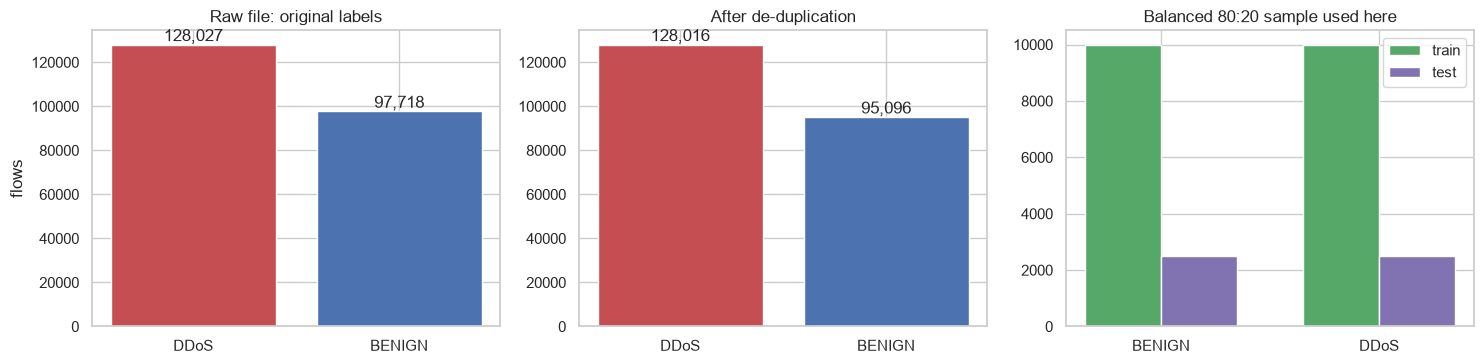

In [6]:
print("dataset: CIC-IDS2017, Friday-WorkingHours-Afternoon-DDos (Hugging Face mirror %s)" % HF_REPO)
print("raw shape:", raw.shape, "| after cleaning:", X_all.shape, "(+ label) | balanced sample:", X_s.shape)
print("\nfeature names (%d):" % len(feature_names))
print(", ".join(feature_names))
print("\noriginal labels and counts (raw file):"); print(raw["Label"].value_counts().to_string())
print("\nbalanced sample, train:", dict(zip(["BENIGN", "DDoS"], np.bincount(y_train).tolist())), "| test:", dict(zip(["BENIGN", "DDoS"], np.bincount(y_test).tolist())))
display(X_tr_raw.describe().T.loc[["Flow Duration", "Total Fwd Packets", "Flow Bytes/s", "Flow Packets/s", "Fwd Packet Length Mean"]].round(2))

fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
cnt = raw["Label"].value_counts()
ax[0].bar(cnt.index, cnt.values, color=[("#c44e52" if k == "DDoS" else "#4c72b0") for k in cnt.index]); ax[0].set_title("Raw file: original labels"); ax[0].set_ylabel("flows")
for i, v in enumerate(cnt.values): ax[0].text(i, v, f"{v:,}", ha="center", va="bottom")
cnt2 = pd.Series(y_all).map({0: "BENIGN", 1: "DDoS"}).value_counts()
ax[1].bar(cnt2.index, cnt2.values, color=[("#c44e52" if k == "DDoS" else "#4c72b0") for k in cnt2.index]); ax[1].set_title("After de-duplication")
for i, v in enumerate(cnt2.values): ax[1].text(i, v, f"{v:,}", ha="center", va="bottom")
w = 0.35
ax[2].bar(np.arange(2) - w/2, np.bincount(y_train), w, label="train", color="#55a868")
ax[2].bar(np.arange(2) + w/2, np.bincount(y_test), w, label="test", color="#8172b2")
ax[2].set_xticks([0, 1]); ax[2].set_xticklabels(["BENIGN", "DDoS"]); ax[2].set_title("Balanced 80:20 sample used here"); ax[2].legend()
plt.tight_layout(); plt.show()

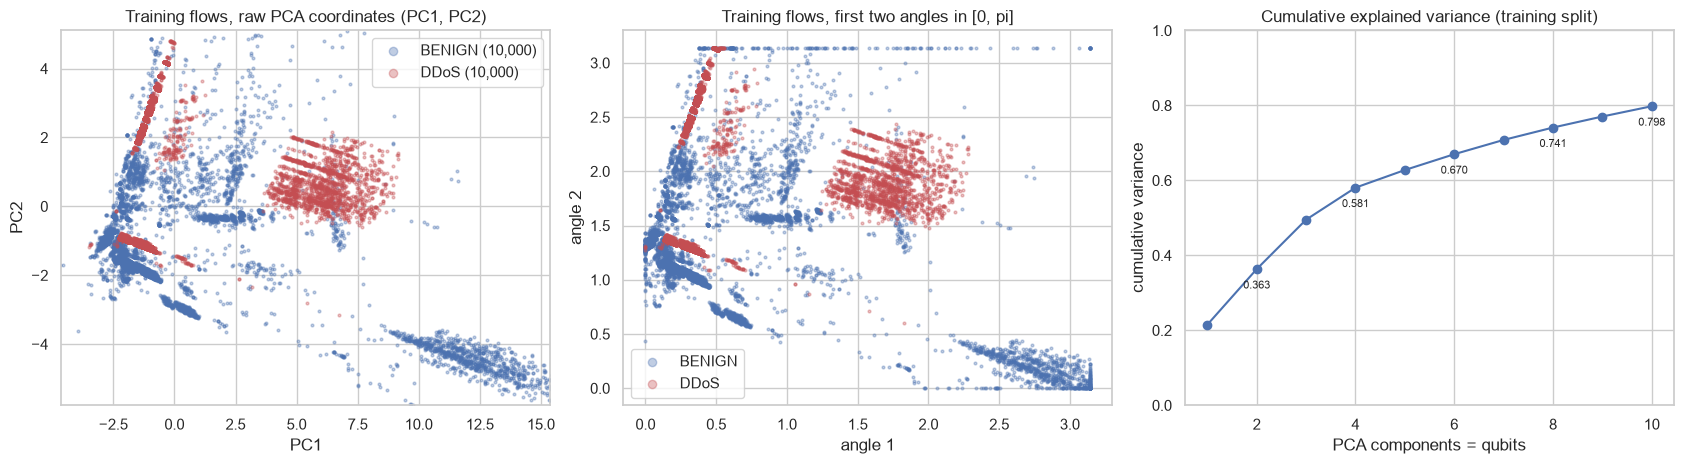

The two classes overlap strongly in the first two components (they carry 36.3 % of the variance), which is why PCA = 2 is hard for every model.


In [7]:
# 2-D scatter of the REAL training flows, coloured by ground truth. (a) raw PCA coordinates, (b) rescaled to [0, pi].
lo, hi = np.percentile(P_tr[:, :2], [1, 99], axis=0)                       # CHOICE: display range = 1st-99th percentile (the flow features are heavy-tailed)
mm = MinMaxScaler((0, np.pi)).fit(np.clip(P_tr[:, :2], lo, hi))            # fitted on the training split only
ang_tr = mm.transform(np.clip(P_tr[:, :2], lo, hi))
names = {0: "BENIGN", 1: "DDoS"}; colors = {0: "#4c72b0", 1: "#c44e52"}
fig, ax = plt.subplots(1, 3, figsize=(17, 4.8))
for lab in (0, 1):
    m = y_train == lab
    ax[0].scatter(P_tr[m, 0], P_tr[m, 1], s=4, alpha=0.35, c=colors[lab], label=f"{names[lab]} ({m.sum():,})")
    ax[1].scatter(ang_tr[m, 0], ang_tr[m, 1], s=4, alpha=0.35, c=colors[lab], label=names[lab])
ax[0].set_xlim(lo[0] - 0.1 * abs(hi[0] - lo[0]), hi[0] + 0.1 * abs(hi[0] - lo[0])); ax[0].set_ylim(lo[1] - 0.1 * abs(hi[1] - lo[1]), hi[1] + 0.1 * abs(hi[1] - lo[1]))
ax[0].set_title("Training flows, raw PCA coordinates (PC1, PC2)"); ax[0].set_xlabel("PC1"); ax[0].set_ylabel("PC2"); ax[0].legend(markerscale=3)
ax[1].set_title("Training flows, first two angles in [0, pi]"); ax[1].set_xlabel("angle 1"); ax[1].set_ylabel("angle 2"); ax[1].legend(markerscale=3)
ax[2].plot(range(1, MAX_PCA + 1), cumvar, "o-"); ax[2].set_title("Cumulative explained variance (training split)")
ax[2].set_xlabel("PCA components = qubits"); ax[2].set_ylabel("cumulative variance"); ax[2].set_ylim(0, 1)
for n_, v_ in zip(range(1, MAX_PCA + 1), cumvar):
    if n_ in PCA_LIST: ax[2].annotate(f"{v_:.3f}", (n_, v_), textcoords="offset points", xytext=(0, -14), ha="center", fontsize=8)
plt.tight_layout(); plt.show()
print("The two classes overlap strongly in the first two components (they carry %.1f %% of the variance), which is why PCA = 2 is hard for every model." % (100 * cumvar[1]))

## 3. The streaming environment, the reward and REINFORCE

The environment is the authors' `IDSStreamEnv` (commit `f7b8a00`). Training flows are put in one fixed random order; an *episode* starts at
a random position and serves 200 consecutive flows, one per step. The state is the PCA vector of the current flow; the action is
`0` (normal) or `1` (attack); the reward is Eq. (6). The next state is simply the next flow, so the action never influences what comes
next: the paper itself says that the Markov property "is satisfied trivially" and that it uses reinforcement learning only as a way to
write the asymmetric cost into the training signal.

REINFORCE (Algorithm 1, Eq. 8): sample one action per flow from the policy, compute the discounted returns $G_t$ of the episode,
normalise them (mean 0, standard deviation 1; the authors' code does this, the paper does not mention it), and take one Adam step on
$-\sum_t G_t \log \pi_\theta(a_t|s_t)$. Because the policy is fixed during an episode and the states do not depend on the actions,
evaluating the policy on all 200 states of an episode **in one batch gives exactly the same probabilities, samples and gradient** as the
authors' step-by-step loop; the notebook batches the episode, which is what makes the quantum policy affordable on a CPU.

In [8]:
class IDSStreamEnv:
    """Authors' streaming environment: fixed random order, random start, episodes of EPISODE_LENGTH consecutive flows."""
    def __init__(self, X, y, episode_length=200, seed=0, reward=REWARD):
        self.X, self.y, self.n, self.L = X, y, len(X), episode_length
        self.rng = np.random.RandomState(seed)
        self.order = self.rng.permutation(self.n)
        self.r_tp, self.r_tn, self.r_fn, self.r_fp = reward
    def episode(self):
        start = self.rng.randint(0, max(1, self.n - self.L))
        idx = self.order[start:start + self.L]
        return self.X[idx], self.y[idx]
    def rewards(self, a, lab):                         # Eq. (6)
        r = np.where((a == 1) & (lab == 1), self.r_tp, 0.0)      # true positive
        r = np.where((a == 0) & (lab == 0), self.r_tn, r)        # true negative
        r = np.where((a == 0) & (lab == 1), self.r_fn, r)        # false negative
        r = np.where((a == 1) & (lab == 0), self.r_fp, r)        # false positive
        return r

def discounted_returns(r, gamma):
    G, out = 0.0, np.empty_like(r)
    for t in range(len(r) - 1, -1, -1):
        G = r[t] + gamma * G; out[t] = G
    return out

def rates(lab, a):
    tp = int(((a == 1) & (lab == 1)).sum()); tn = int(((a == 0) & (lab == 0)).sum())
    fp = int(((a == 1) & (lab == 0)).sum()); fn = int(((a == 0) & (lab == 1)).sum())
    return (fp / (fp + tn) if fp + tn else 0.0), (fn / (fn + tp) if fn + tp else 0.0), (tp + tn) / len(lab)

def train_reinforce(policy, env, episodes, lr=LR, gamma=GAMMA):
    opt = torch.optim.Adam(policy.parameters(), lr=lr)
    hist = {"reward": [], "fpr": [], "fnr": [], "acc": []}
    t0 = time.time()
    for ep in range(episodes):
        Xb, yb = env.episode()
        probs = policy(torch.as_tensor(Xb, dtype=torch.float32))          # one batched forward = 200 sequential steps
        dist = torch.distributions.Categorical(probs)
        act = dist.sample(); logp = dist.log_prob(act); a = act.numpy()
        r = env.rewards(a, yb)
        G = torch.as_tensor(discounted_returns(r, gamma), dtype=torch.float32)
        if len(G) > 1 and G.std().item() > 1e-8:                          # CHOICE: per-episode normalisation (authors' code)
            G = (G - G.mean()) / (G.std() + 1e-9)
        loss = -(logp * G).sum()
        opt.zero_grad(); loss.backward(); opt.step()
        fpr, fnr, acc = rates(yb, a)
        hist["reward"].append(float(r.sum())); hist["fpr"].append(fpr); hist["fnr"].append(fnr); hist["acc"].append(acc)
    hist["time"] = time.time() - t0
    return hist

@torch.no_grad()
def evaluate(policy, X, y):
    p1 = policy(torch.as_tensor(X, dtype=torch.float32))[:, 1].numpy()      # probability of "attack"
    pred = (p1 > 0.5).astype(int)                                           # argmax of the two action probabilities (authors' evaluation)
    cm = confusion_matrix(y, pred, labels=[0, 1]); tn, fp, fn, tp = cm.ravel()
    prec = tp / (tp + fp) if tp + fp else 0.0; rec = tp / (tp + fn) if tp + fn else 0.0
    f1 = 2 * prec * rec / (prec + rec) if prec + rec else 0.0
    auc = roc_auc_score(y, p1) if len(np.unique(p1)) > 1 else 0.5
    return dict(acc=(tp + tn) / len(y), prec=prec, rec=rec, f1=f1, fpr=fp / (fp + tn), fnr=fn / (fn + tp), auc=auc, cm=cm, p1=p1)

# sanity check of the reward function on a hand-made case: [TP, FN, FP, TN]
_a, _l = np.array([1, 0, 1, 0]), np.array([1, 1, 0, 0])
print("rewards for [TP, FN, FP, TN]:", IDSStreamEnv(P_tr[:, :2], y_train).rewards(_a, _l), "(expected [ 2. -2. -0.5  2. ])")

rewards for [TP, FN, FP, TN]: [ 2.  -2.  -0.5  2. ] (expected [ 2. -2. -0.5  2. ])


## 4. The two policies

**Classical RL policy** (authors' `ClassicalPolicy`): `Linear(n,64)` - ReLU - `Linear(64,64)` - ReLU - `Linear(64,2)` - softmax.

**Hybrid quantum policy, VQRL-IQP** (authors' `HybridPolicy`): `Linear(n,n)` - `tanh` -> **quantum layer** -> `Linear(n,32)` - `tanh` -
`Linear(32,2)` - softmax. The quantum layer is the PennyLane circuit

$$|\psi(x,\theta)\rangle = U_\text{SEL}(\theta)\,U_\text{IQP}(x)\,|0\rangle^{\otimes n},\qquad z_i = \langle\psi|Z_i|\psi\rangle,\quad i=0..n-1,$$

with `qml.IQPEmbedding` (Hadamards, one `RZ(x_i)` per qubit, one `MultiRZ(x_i x_j)` per pair, one repetition) and
`qml.StronglyEntanglingLayers` with $L=2$ layers ($3nL$ trainable angles, initialised uniformly in $[0,2\pi]$ as `TorchLayer` does).

**Simulation.** The exact action of this circuit on a batch of 200 flows is computed by a small PyTorch statevector simulator
(`CircuitSim`): the IQP state is written in closed form (a uniform superposition with a diagonal phase
$\exp\{-\tfrac{i}{2}[\sum_i x_i s_i + \sum_{i<j} x_i x_j s_i s_j]\}$, $s_i=\pm1$), the Rot gates and CNOT permutations of the strongly
entangling layers are applied to the batched state, and the $Z_i$ expectation values are read from the probabilities. The next section draws
the real PennyLane circuit and proves numerically (values *and* gradients, including against the parameter-shift rule of the paper's
Table 1) that `CircuitSim` computes the same function, then compares the speed of one 200-flow episode with PennyLane's own `TorchLayer`.
Training uses single-precision complex numbers (values agree with the double-precision check to about 1e-6, far below the noise of REINFORCE); the
verification below is done in double precision.

In [9]:
class CircuitSim:
    """Exact batched statevector simulation of  IQPEmbedding(x) [or AngleEmbedding(x)] -> StronglyEntanglingLayers(weights) -> <Z_i>."""
    def __init__(self, n, n_layers, embedding="iqp", dtype=torch.complex128):
        self.n, self.L, self.embedding, self.cd = n, n_layers, embedding, dtype
        self.rd = torch.float64 if dtype == torch.complex128 else torch.float32
        axes, outs = string.ascii_lowercase[:n], string.ascii_uppercase[:n]
        self.eq = "".join(f"{outs[i]}{axes[i]}," for i in range(n)) + "z" + axes + "->z" + outs   # all n single-qubit gates of a layer in one einsum
        z = np.arange(2 ** n)[:, None]
        bits = (z >> (n - 1 - np.arange(n))[None, :]) & 1                      # wire 0 = most significant bit (PennyLane order)
        self.S = torch.tensor(1.0 - 2.0 * bits, dtype=self.rd)                 # S[z, i] = eigenvalue of Z_i on basis state z
        self.I, self.J = np.triu_indices(n, k=1)
        self.SS = self.S[:, self.I] * self.S[:, self.J]
        self.perms = []                                                         # CNOT ring of each StronglyEntanglingLayers layer
        for l in range(n_layers):
            r = (l % (n - 1)) + 1 if n > 1 else 0                              # PennyLane default range of layer l
            idx = np.arange(2 ** n)
            for i in range(n if n > 1 else 0):
                c, t = i, (i + r) % n
                cb = (idx >> (n - 1 - c)) & 1
                idx = np.where(cb == 1, idx ^ (1 << (n - 1 - t)), idx)
            inv = np.empty_like(idx); inv[idx] = np.arange(2 ** n)
            self.perms.append(torch.tensor(inv, dtype=torch.long))

    def _embed(self, x):
        n = self.n
        if self.embedding == "iqp":
            lin = x @ self.S.T
            quad = (x[:, self.I] * x[:, self.J]) @ self.SS.T
            return (torch.exp(-0.5j * (lin + quad)) / np.sqrt(2 ** n)).to(self.cd)   # H^n, then RZ(x_i) and MultiRZ(x_i x_j) (all diagonal)
        psi = torch.ones(x.shape[0], 1, dtype=torch.complex128)                # AngleEmbedding (rotation X): RX(x_i)|0>
        x = x.double()
        for q in range(n):
            c, s = torch.cos(x[:, q] / 2), torch.sin(x[:, q] / 2)
            qb = torch.stack([c.to(torch.complex128), -1j * s.to(torch.complex128)], dim=1)
            psi = (psi[:, :, None] * qb[:, None, :]).reshape(x.shape[0], -1)
        return psi.to(self.cd)

    @staticmethod
    def _rots(w):                                                              # w: (n, 3) -> (n, 2, 2); qml.Rot = RZ(omega) RY(theta) RZ(phi)
        phi, theta, omega = w[:, 0], w[:, 1], w[:, 2]
        c, s = torch.cos(theta / 2), torch.sin(theta / 2)
        e = lambda a: torch.exp(1j * a)
        g00, g01 = e(-(phi + omega) / 2) * c, -e((phi - omega) / 2) * s
        g10, g11 = e(-(phi - omega) / 2) * s, e((phi + omega) / 2) * c
        return torch.stack([torch.stack([g00, g01], -1), torch.stack([g10, g11], -1)], -2)

    def expvals(self, x, weights):
        n, B = self.n, x.shape[0]
        psi = self._embed(x.to(self.rd))
        weights = weights.to(self.rd)
        for l in range(self.L):
            G = self._rots(weights[l]).to(self.cd)
            psi = torch.einsum(self.eq, *[G[i] for i in range(n)], psi.reshape((B,) + (2,) * n)).reshape(B, -1)   # Rot on every wire
            psi = psi[:, self.perms[l]]                                         # CNOT ring of the layer
        prob = psi.real ** 2 + psi.imag ** 2
        return prob @ self.S                                                    # <Z_i>, shape (B, n)

class ClassicalPolicy(nn.Module):
    def __init__(self, n_in, n_actions=2):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(n_in, 64), nn.ReLU(), nn.Linear(64, 64), nn.ReLU(), nn.Linear(64, n_actions))
    def forward(self, x):
        return torch.softmax(self.net(x), dim=-1)

class HybridPolicy(nn.Module):
    """Linear -> tanh -> quantum layer ('iqp' | 'angle' | 'none' = bypass) -> Linear -> tanh -> Linear -> softmax."""
    def __init__(self, n, n_layers=2, embedding="iqp", n_actions=2):
        super().__init__()
        self.embedding = embedding
        self.fc_in = nn.Linear(n, n)
        if embedding != "none":
            self.sim = CircuitSim(n, n_layers, embedding, dtype=torch.complex64)   # CHOICE: single precision for training speed (values agree to ~1e-6)
            self.q_weights = nn.Parameter(torch.rand(n_layers, n, 3) * 2 * np.pi)      # TorchLayer default init U[0, 2 pi]
        self.fc_out = nn.Sequential(nn.Linear(n, 32), nn.Tanh(), nn.Linear(32, n_actions))
    def angles(self, x):
        return torch.tanh(self.fc_in(x))
    def forward(self, x):
        a = self.angles(x)
        z = self.sim.expvals(a, self.q_weights).float() if self.embedding != "none" else a
        return torch.softmax(self.fc_out(z), dim=-1)

def make_qnode(n, embedding="iqp", diff_method="backprop"):
    """The PennyLane circuit of the authors' hybrid policy (their `build_hybrid_policy` qnode)."""
    dev = qml.device("default.qubit", wires=n)
    @qml.qnode(dev, interface="torch", diff_method=diff_method)
    def qnode(inputs, weights):
        (qml.IQPEmbedding if embedding == "iqp" else qml.AngleEmbedding)(inputs, wires=range(n))
        qml.StronglyEntanglingLayers(weights, wires=range(n))
        return [qml.expval(qml.PauliZ(i)) for i in range(n)]
    return qnode

class PennyLaneHybridPolicy(nn.Module):
    """The authors' hybrid policy with PennyLane's TorchLayer (slow; used for verification and if USE_PENNYLANE_LAYER = True)."""
    def __init__(self, n, n_layers=2, embedding="iqp", n_actions=2):
        super().__init__()
        from pennylane.qnn import TorchLayer
        self.fc_in = nn.Linear(n, n)
        self.ql = TorchLayer(make_qnode(n, embedding), {"weights": (n_layers, n, 3)})
        self.fc_out = nn.Sequential(nn.Linear(n, 32), nn.Tanh(), nn.Linear(32, n_actions))
    def forward(self, x):
        return torch.softmax(self.fc_out(self.ql(torch.tanh(self.fc_in(x)))), dim=-1)

def make_policy(kind, n):
    if kind == "classical": return ClassicalPolicy(n)
    if kind == "iqp":       return PennyLaneHybridPolicy(n, N_LAYERS, "iqp") if USE_PENNYLANE_LAYER else HybridPolicy(n, N_LAYERS, "iqp")
    if kind == "angle":     return HybridPolicy(n, N_LAYERS, "angle")
    if kind == "noquantum": return HybridPolicy(n, N_LAYERS, "none")
    raise ValueError(kind)
LABEL = {"classical": "Classical RL", "iqp": "VQRL-IQP", "angle": "VQRL-Angle (ablation)", "noquantum": "Hybrid without quantum layer (ablation)"}

## Quantum Circuit Architecture

The circuit that the hybrid policy executes, drawn from the real PennyLane QNode (`qml.draw_mpl`). Three drawings, one per distinct
architecture that the notebook trains: (a) the IQP-embedded circuit at 4 qubits, fully expanded into gates, so that the encoding
(Hadamards, `RZ(x_i)`, all-to-all `MultiRZ(x_i x_j)` = the IQP phase layer), the two strongly entangling layers (a `Rot` on every qubit
followed by a CNOT ring with range 1, then range 2) and the Pauli-Z measurements are all visible; (b) the same IQP architecture at 8 qubits,
the paper's best VQRL-IQP size, also fully expanded (28 `MultiRZ` gates, 16 `Rot` gates, 16 CNOTs; the picture is wide, zoom in to read it); (c) the ablation circuit with `AngleEmbedding` (one `RX(x_i)` per qubit) instead of IQP, 4 qubits.

*Assumptions where the paper is silent.* The paper's Fig. 2 and Table 1 do not give the IQP repetition count (here the PennyLane default,
`n_repeats = 1`), the entangling ranges (PennyLane defaults: range 1 in layer 1, range 2 in layer 2 for `n > 2`; the paper's "full
all-to-all topology" is not what `StronglyEntanglingLayers` does, it uses a CNOT ring whose range grows with the layer index), nor the
classical layers around the circuit (taken from the authors' code). The drawn circuits are exactly the authors' QNode.

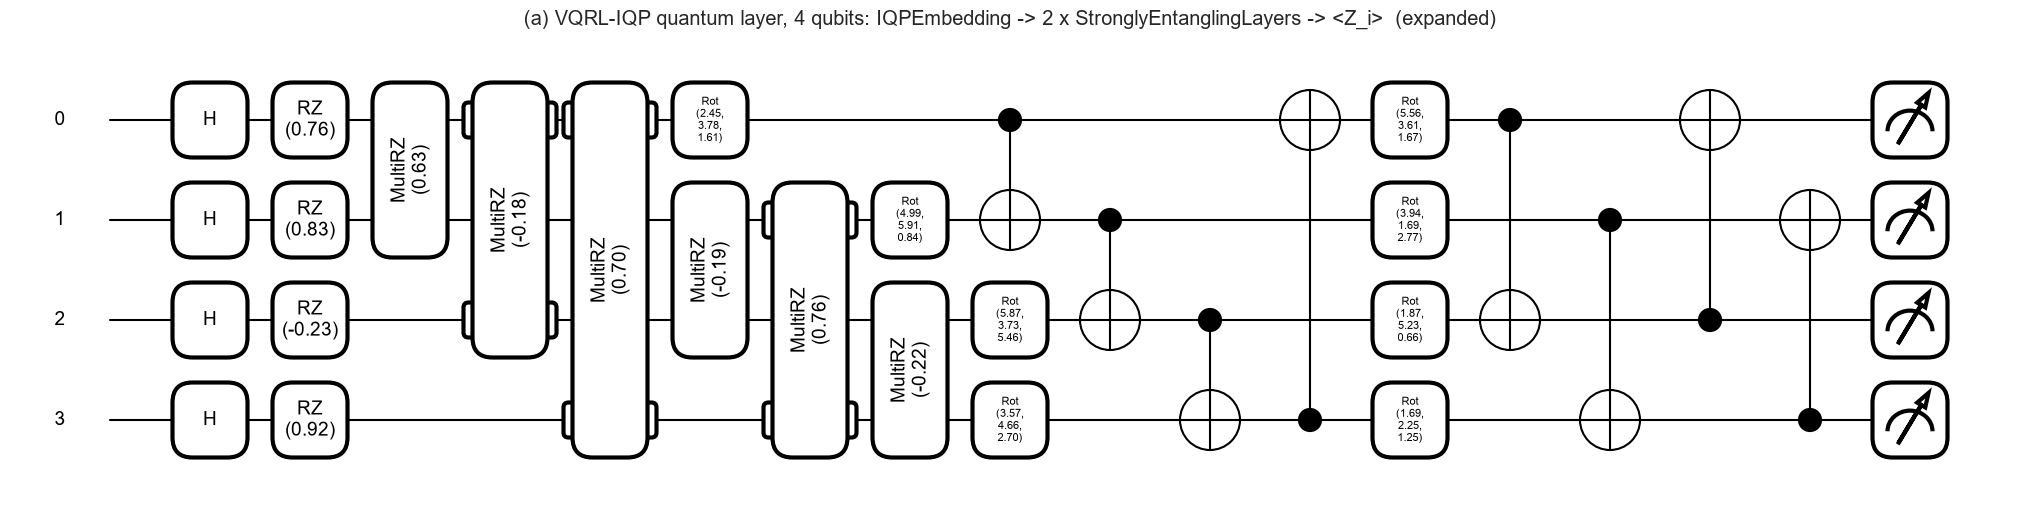

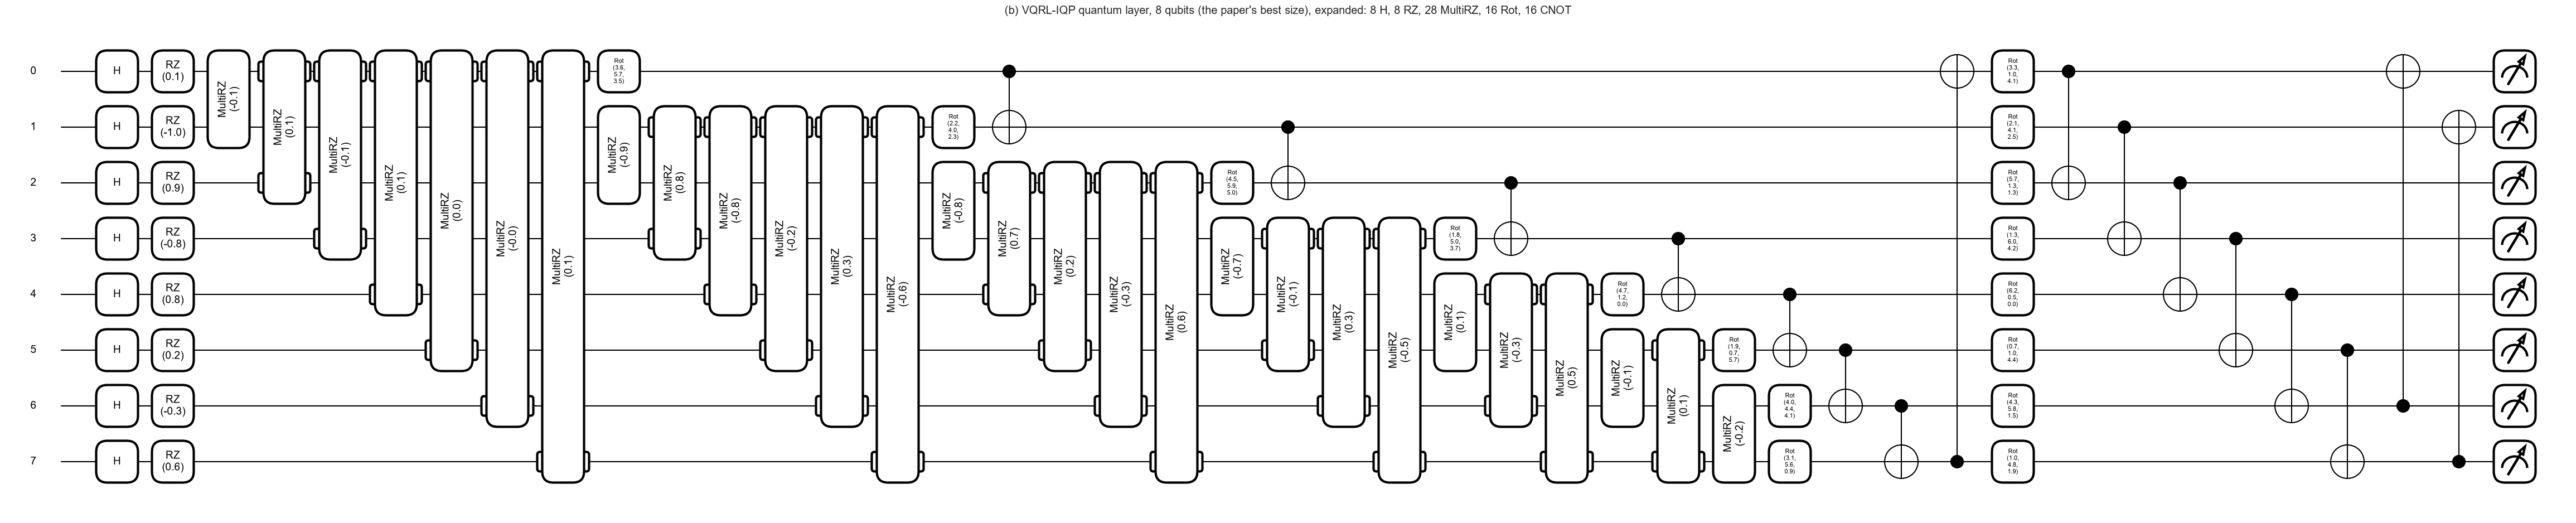

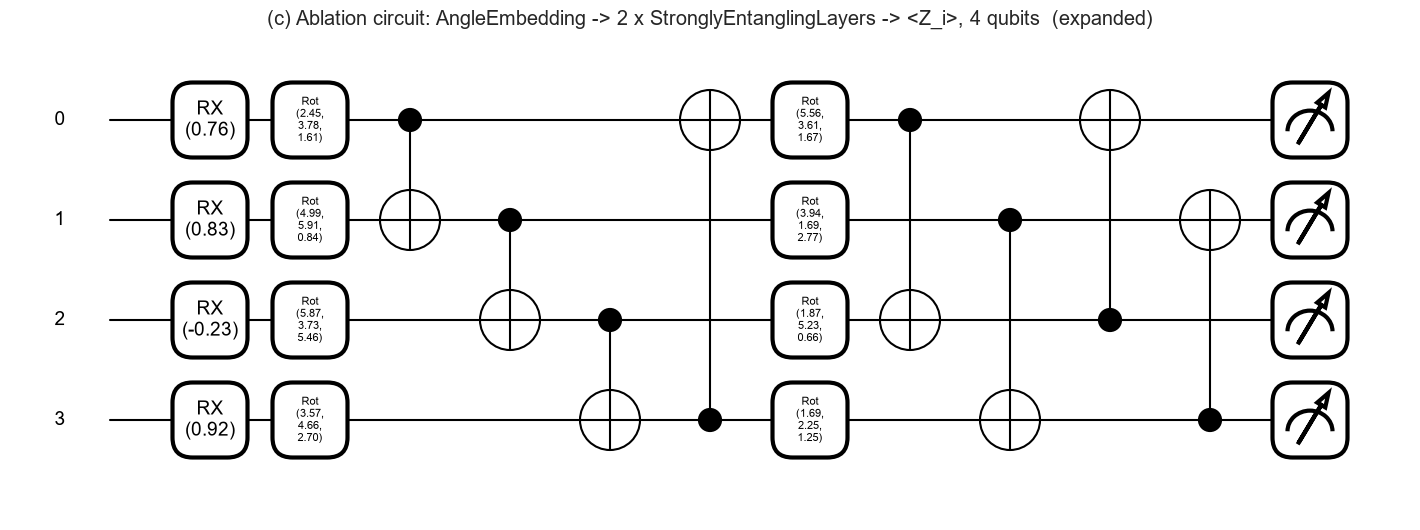

,embedding,qubits,depth,gates,trainable_quantum_params,formula_3nL,params_whole_hybrid_policy
0,iqp,2,9,13,12,12,180
1,iqp,4,14,30,24,24,270
2,angle,4,9,20,24,24,270
3,iqp,6,19,51,36,36,368
4,iqp,8,24,76,48,48,474
5,angle,8,15,40,48,48,474
6,iqp,10,29,105,60,60,588


Trainable parameters of the quantum layer = 3 x n x L (paper Table 1), measured on the weight tensor of the policy.
Measurements: Pauli-Z expectation value of every qubit (Eq. 11); simulation mode: exact statevector (shots=None).


In [10]:
g = torch.Generator().manual_seed(SEED)
def demo_inputs(n):
    return (torch.rand(n, generator=g) * 2 - 1), (torch.rand(N_LAYERS, n, 3, generator=g) * 2 * np.pi)

# (a) IQP, 4 qubits, expanded to device gates
x4, w4 = demo_inputs(4)
fig, ax = qml.draw_mpl(make_qnode(4, "iqp"), level="device", decimals=2)(x4, w4)
fig.suptitle("(a) VQRL-IQP quantum layer, 4 qubits: IQPEmbedding -> 2 x StronglyEntanglingLayers -> <Z_i>  (expanded)", y=1.02); plt.show()
# (b) IQP at the paper's best size, template level
nb = PCA_QUANTUM_BEST
xb_, wb_ = demo_inputs(nb)
fig, ax = qml.draw_mpl(make_qnode(nb, "iqp"), level="device", decimals=1)(xb_, wb_)
fig.suptitle(f"(b) VQRL-IQP quantum layer, {nb} qubits (the paper's best size), expanded: 8 H, 8 RZ, 28 MultiRZ, 16 Rot, 16 CNOT", y=1.02); plt.show()
# (c) AngleEmbedding ablation
fig, ax = qml.draw_mpl(make_qnode(4, "angle"), level="device", decimals=2)(x4, w4)
fig.suptitle("(c) Ablation circuit: AngleEmbedding -> 2 x StronglyEntanglingLayers -> <Z_i>, 4 qubits  (expanded)", y=1.02); plt.show()

rows = []
for n_ in sorted(set(PCA_LIST)):
    for emb in ("iqp", "angle"):
        if emb == "angle" and n_ != 4 and n_ != nb: continue
        xx, ww = demo_inputs(n_)
        sp = qml.specs(make_qnode(n_, emb), level="device")(xx, ww)
        q_params = N_LAYERS * n_ * 3
        hybrid = sum(p.numel() for p in HybridPolicy(n_, N_LAYERS, emb).parameters())
        rows.append(dict(embedding=emb, qubits=n_, depth=sp.resources.depth, gates=sp.resources.num_gates,
                         trainable_quantum_params=q_params, formula_3nL=3 * n_ * N_LAYERS, params_whole_hybrid_policy=hybrid))
arch = pd.DataFrame(rows); display(arch)
assert (arch.trainable_quantum_params == arch.formula_3nL).all()
print("Trainable parameters of the quantum layer = 3 x n x L (paper Table 1), measured on the weight tensor of the policy.")
print("Measurements: Pauli-Z expectation value of every qubit (Eq. 11); simulation mode: exact statevector (shots=None).")

In [11]:
# ---- proof that CircuitSim = the PennyLane circuit: values, gradients (incl. parameter-shift), and the whole hybrid policy ----
torch.manual_seed(SEED)
checks = []
for emb in ("iqp", "angle"):
    for n_ in sorted({2, 3, 4, 6} | ({nb} if emb == "iqp" else set())):
        sim = CircuitSim(n_, N_LAYERS, emb)                   # double precision for the check
        qn_bp, qn_ps = make_qnode(n_, emb, "backprop"), make_qnode(n_, emb, "parameter-shift")
        x = (torch.rand(3, n_, dtype=torch.float64) * 2 - 1); w = (torch.rand(N_LAYERS, n_, 3, dtype=torch.float64) * 2 * np.pi)
        ref = torch.stack([torch.stack(qn_bp(x[b], w), -1) for b in range(3)])
        got = sim.expvals(x, w)
        coef = torch.rand(3, n_, dtype=torch.float64)
        # gradients of a scalar loss wrt weights and inputs: autograd through CircuitSim vs the parameter-shift rule on the QNode
        xs, ws = x.clone().requires_grad_(), w.clone().requires_grad_()
        (sim.expvals(xs, ws) * coef).sum().backward()
        g_sim = torch.cat([xs.grad.flatten(), ws.grad.flatten()])
        xp, wp = x.clone().requires_grad_(), w.clone().requires_grad_()
        loss = sum((torch.stack(qn_ps(xp[b], wp), -1) * coef[b]).sum() for b in range(3)); loss.backward()
        g_ps = torch.cat([xp.grad.flatten(), wp.grad.flatten()])
        checks.append(dict(embedding=emb, qubits=n_, max_value_diff=float((ref - got).abs().max()), max_grad_diff_vs_parameter_shift=float((g_sim - g_ps).abs().max())))
chk = pd.DataFrame(checks); display(chk)
assert (chk.max_value_diff < 1e-9).all() and (chk.max_grad_diff_vs_parameter_shift < 1e-6).all()
print("CircuitSim reproduces the PennyLane QNode (values and parameter-shift gradients) for every size and both embeddings.")
# the single-precision simulator used for training agrees with the double-precision one
for emb in ("iqp", "angle"):
    n_ = nb; xx = torch.rand(50, n_, dtype=torch.float64) * 2 - 1; ww = torch.rand(N_LAYERS, n_, 3, dtype=torch.float64) * 2 * np.pi
    d_ = float((CircuitSim(n_, N_LAYERS, emb).expvals(xx, ww) - CircuitSim(n_, N_LAYERS, emb, dtype=torch.complex64).expvals(xx, ww).double()).abs().max())
    print(f"single vs double precision ({emb}, {n_} qubits): max |difference| of <Z_i> = {d_:.1e}"); assert d_ < 1e-5

# the whole hybrid policy against the authors' TorchLayer policy with identical weights, and speed of one 200-flow episode
n_ = nb
fast, slow = HybridPolicy(n_, N_LAYERS, "iqp"), PennyLaneHybridPolicy(n_, N_LAYERS, "iqp")
with torch.no_grad():
    slow.fc_in.load_state_dict(fast.fc_in.state_dict()); slow.fc_out.load_state_dict(fast.fc_out.state_dict())
    slow.ql.qnode_weights["weights"].copy_(fast.q_weights)
xb200 = torch.as_tensor(P_tr[:EPISODE_LENGTH, :n_])
t0 = time.time(); pf = fast(xb200); pf[:, 1].sum().backward(); t_fast = time.time() - t0
t0 = time.time(); ps = slow(xb200); ps[:, 1].sum().backward(); t_slow = time.time() - t0
print(f"hybrid policy outputs, CircuitSim vs PennyLane TorchLayer ({n_} qubits, 200 flows): max |difference| = {float((pf - ps).abs().max()):.2e}")
print(f"gradient wrt the quantum weights: max |difference| = {float((fast.q_weights.grad - slow.ql.qnode_weights['weights'].grad).abs().max()):.2e}")
print(f"one forward+backward of an episode: CircuitSim {t_fast*1000:.0f} ms | PennyLane TorchLayer {t_slow*1000:.0f} ms  (speed-up x{t_slow/max(t_fast,1e-9):.0f})")
assert float((pf - ps).abs().max()) < 1e-4

,embedding,qubits,max_value_diff,max_grad_diff_vs_parameter_shift
0,iqp,2,2.775558e-16,3.330669e-16
1,iqp,3,4.996004e-16,8.881784e-16
2,iqp,4,4.440892e-16,1.332268e-15
3,iqp,6,4.302114e-16,6.661338e-16
4,iqp,8,4.510281e-16,7.494005e-16
5,angle,2,0.000000e+00,2.220446e-16
6,angle,3,2.775558e-17,3.330669e-16
7,angle,4,1.665335e-16,6.661338e-16
8,angle,6,2.220446e-16,6.242915e-16


CircuitSim reproduces the PennyLane QNode (values and parameter-shift gradients) for every size and both embeddings.
single vs double precision (iqp, 8 qubits): max |difference| of <Z_i> = 2.7e-07
single vs double precision (angle, 8 qubits): max |difference| of <Z_i> = 5.3e-07


hybrid policy outputs, CircuitSim vs PennyLane TorchLayer (8 qubits, 200 flows): max |difference| = 5.96e-08
gradient wrt the quantum weights: max |difference| = 1.55e-06
one forward+backward of an episode: CircuitSim 122 ms | PennyLane TorchLayer 825 ms  (speed-up x7)


## 5. Training the two agents at the paper's best configurations (Table 2, Figures 3-6)

The paper's Table 2 compares classical RL at PCA = 6 with VQRL-IQP at PCA = 8, each "at its respective optimal PCA configuration",
as *best single runs*. The helper below trains one agent (`run_cached` remembers every finished run so that the later sections reuse
them instead of retraining). The cell trains the two best-configuration agents with `SEED` and draws the paper's Figure 3 (cumulative
reward per episode), Figures 4 and 5 (false-negative and false-positive rate per training episode), Figure 6 (confusion matrices on the
held-out test split, row-normalised as in the paper) and, as an extra, the angles that the trained circuit really receives.

In [12]:
RUNS = {}
def run_one(kind, n, seed, reward=REWARD, episodes=None):
    episodes = EPISODES if episodes is None else episodes
    torch.manual_seed(seed); np.random.seed(seed)
    env = IDSStreamEnv(P_tr[:, :n], y_train, EPISODE_LENGTH, seed, reward)
    pol = make_policy(kind, n)
    hist = train_reinforce(pol, env, episodes)
    m = evaluate(pol, P_te[:, :n], y_test)
    m.update(kind=kind, n=n, seed=seed, reward=reward, hist=hist, time=hist["time"], policy=pol)
    return m
def run_cached(kind, n, seed, reward=REWARD, episodes=None):
    key = (kind, n, seed, tuple(reward), EPISODES if episodes is None else episodes)
    if key not in RUNS:
        RUNS[key] = run_one(kind, n, seed, reward, episodes)
    return RUNS[key]
def smooth(v, k=SMOOTH):
    v = np.asarray(v, float); k = max(1, min(k, len(v)))
    return np.convolve(v, np.ones(k) / k, mode="valid")
def row(m):
    return {k: m[k] for k in ("acc", "prec", "rec", "f1", "fpr", "fnr", "auc")} | {"time_s": m["time"]}

t0 = time.time()
rc = run_cached("classical", PCA_CLASSICAL_BEST, SEED)
print(f"classical RL, PCA {PCA_CLASSICAL_BEST}: trained {EPISODES} episodes in {rc['time']:.1f}s")
rq = run_cached("iqp", PCA_QUANTUM_BEST, SEED)
print(f"VQRL-IQP,     PCA {PCA_QUANTUM_BEST}: trained {EPISODES} episodes in {rq['time']:.1f}s")
tab2 = pd.DataFrame({f"Classical RL (PCA {PCA_CLASSICAL_BEST})": row(rc), f"VQRL-IQP (PCA {PCA_QUANTUM_BEST})": row(rq)}).T
display(tab2.round(4))
print("paper Table 2: RL (PCA 6): acc 0.9602 prec 0.9928 rec 0.9275 F1 0.9590 | VQRL-IQP (PCA 8): acc 0.9582 prec 0.9228 rec 0.9988 F1 0.9593")

classical RL, PCA 6: trained 1000 episodes in 7.2s


VQRL-IQP,     PCA 8: trained 1000 episodes in 115.9s


,acc,prec,rec,f1,fpr,fnr,auc,time_s
Classical RL (PCA 6),0.8958,0.849,0.9628,0.9023,0.1712,0.0372,0.8725,7.1813
VQRL-IQP (PCA 8),0.7590,0.676,0.9948,0.8050,0.4768,0.0052,0.9724,115.9304


paper Table 2: RL (PCA 6): acc 0.9602 prec 0.9928 rec 0.9275 F1 0.9590 | VQRL-IQP (PCA 8): acc 0.9582 prec 0.9228 rec 0.9988 F1 0.9593


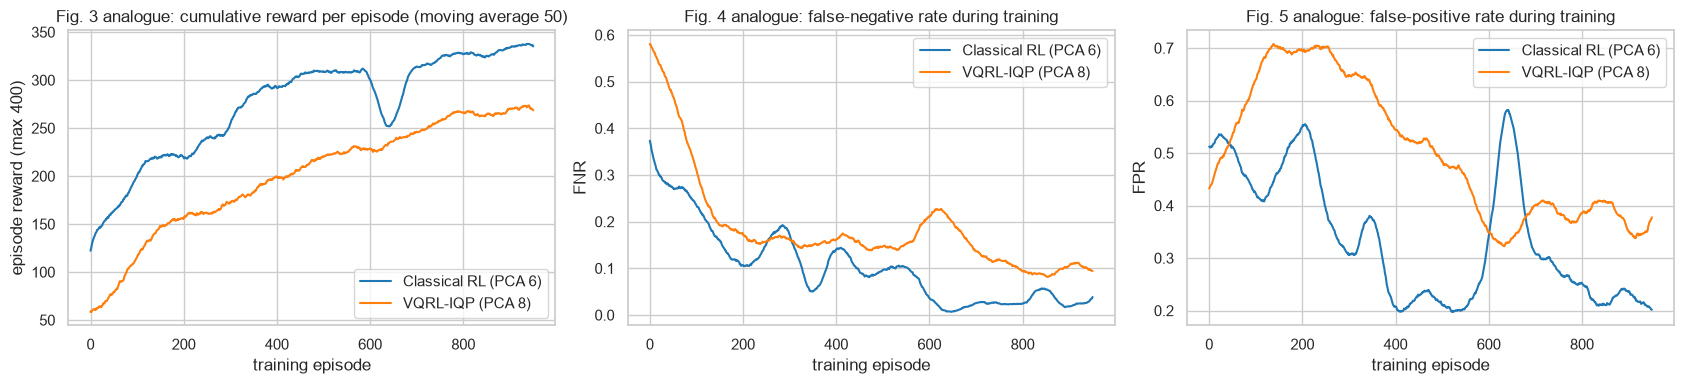

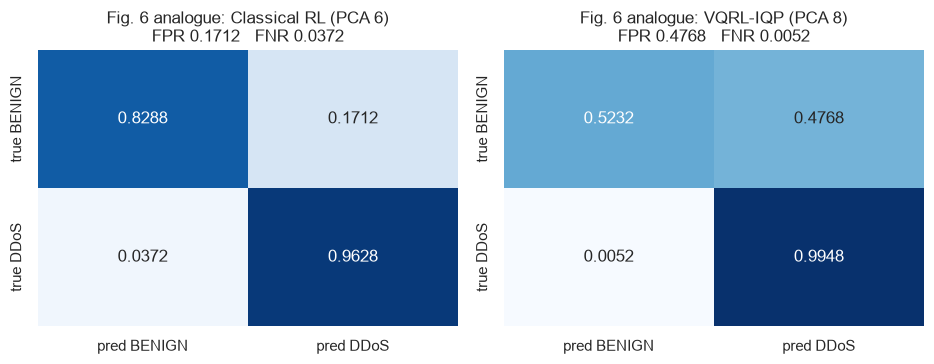

paper Fig. 6: VQRL-IQP FNR 0.0012 and FPR 0.0812 at PCA 8


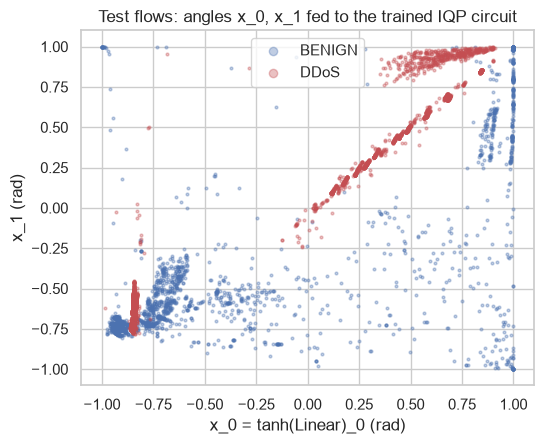

In [13]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4))
for m, c, nm in ((rc, "tab:blue", f"Classical RL (PCA {PCA_CLASSICAL_BEST})"), (rq, "tab:orange", f"VQRL-IQP (PCA {PCA_QUANTUM_BEST})")):
    h = m["hist"]
    ax[0].plot(smooth(h["reward"]), c=c, label=nm); ax[1].plot(smooth(h["fnr"]), c=c, label=nm); ax[2].plot(smooth(h["fpr"]), c=c, label=nm)
ax[0].set_title(f"Fig. 3 analogue: cumulative reward per episode (moving average {SMOOTH})"); ax[0].set_ylabel("episode reward (max 400)")
ax[1].set_title("Fig. 4 analogue: false-negative rate during training"); ax[1].set_ylabel("FNR")
ax[2].set_title("Fig. 5 analogue: false-positive rate during training"); ax[2].set_ylabel("FPR")
for a in ax: a.set_xlabel("training episode"); a.legend()
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(1, 2, figsize=(9.5, 3.8))
for a, m, nm in ((ax[0], rc, f"Classical RL (PCA {PCA_CLASSICAL_BEST})"), (ax[1], rq, f"VQRL-IQP (PCA {PCA_QUANTUM_BEST})")):
    cmn = m["cm"] / m["cm"].sum(1, keepdims=True)
    sns.heatmap(cmn, annot=True, fmt=".4f", cmap="Blues", vmin=0, vmax=1, cbar=False, ax=a, xticklabels=["pred BENIGN", "pred DDoS"], yticklabels=["true BENIGN", "true DDoS"])
    a.set_title(f"Fig. 6 analogue: {nm}\nFPR {m['fpr']:.4f}   FNR {m['fnr']:.4f}")
plt.tight_layout(); plt.show()
print("paper Fig. 6: VQRL-IQP FNR 0.0012 and FPR 0.0812 at PCA 8")

# the angles that the trained circuit really receives (output of Linear + tanh), first two qubits, real test flows
with torch.no_grad():
    ang = rq["policy"].angles(torch.as_tensor(P_te[:, :PCA_QUANTUM_BEST])).numpy()
fig, ax = plt.subplots(1, 1, figsize=(5.6, 4.6))
for lab in (0, 1):
    mk = y_test == lab; ax.scatter(ang[mk, 0], ang[mk, 1], s=4, alpha=0.35, c=colors[lab], label=names[lab])
ax.set_title("Test flows: angles x_0, x_1 fed to the trained IQP circuit"); ax.set_xlabel("x_0 = tanh(Linear)_0 (rad)"); ax.set_ylabel("x_1 (rad)"); ax.legend(markerscale=3)
plt.tight_layout(); plt.show()

## 6. PCA sweep and repeated runs (Tables 3, 4, 5 and 6; Figures 7-9)

The paper reports three related things. Table 3 shows the *best single run* at each PCA size, "individually tuned" by a procedure it does not
describe. Table 6 / Figure 9 show a sweep under one **fixed** budget and hyper-parameter set, in which VQRL-IQP collapses to the all-attack policy
for PCA >= 6. Tables 4 and 5 retrain the best configurations several times and give mean +/- standard deviation and ROC-AUC. All three
come from the same experiment here: for every PCA size and for both agents, `N_SEEDS` independent runs with the same fixed budget
(`EPISODES` episodes, one hyper-parameter set), each with a different seed for the policy initialisation, the environment order and the action
sampling. The sweep prints the mean +/- std, the fraction of runs that collapsed to the all-attack or all-normal policy, and, for comparison with
the paper's Table 3, the best seed chosen **on the test set** (which is optimistic; the paper does the same).

In [14]:
t_sweep = time.time()
for n_ in PCA_LIST:
    for kind in ("classical", "iqp"):
        t1 = time.time()
        for k in range(N_SEEDS_BY_PCA[n_]):
            run_cached(kind, n_, SEED + k)
        print(f"PCA {n_:2d} {LABEL[kind]:13s}: {N_SEEDS_BY_PCA[n_]} seeds in {time.time()-t1:6.1f}s", flush=True)
print(f"sweep finished in {(time.time()-t_sweep)/60:.1f} min")

recs = []
for (kind, n_, seed, rw, ep), m in RUNS.items():
    if tuple(rw) == tuple(REWARD) and ep == EPISODES and kind in ("classical", "iqp") and n_ in PCA_LIST:
        recs.append(dict(model=LABEL[kind], kind=kind, n=n_, seed=seed, **row(m)))
sweep = pd.DataFrame(recs).sort_values(["n", "kind", "seed"]).reset_index(drop=True)
sweep["collapsed_all_attack"] = (sweep.fpr >= 0.99) & (sweep.fnr <= 0.01)
sweep["collapsed_all_normal"] = (sweep.fpr <= 0.01) & (sweep.fnr >= 0.99)
metrics = ["acc", "prec", "rec", "f1", "fpr", "fnr", "auc", "time_s"]
agg = sweep.groupby(["n", "model"])[metrics].agg(["mean", "std"])
fmt = pd.DataFrame({m: agg[m]["mean"].map("{:.4f}".format) + " +/- " + agg[m]["std"].fillna(0).map("{:.4f}".format) for m in metrics})
fmt["VarExp"] = [round(float(cumvar[n_ - 1]), 4) for n_, _ in fmt.index]
fmt["collapsed all-attack (runs)"] = [int(sweep[(sweep.n == n_) & (sweep.model == mo)].collapsed_all_attack.sum()) for n_, mo in fmt.index]
fmt["collapsed all-normal (runs)"] = [int(sweep[(sweep.n == n_) & (sweep.model == mo)].collapsed_all_normal.sum()) for n_, mo in fmt.index]
print("Mean +/- std over seeds, fixed budget (Table 6 / Table 4 analogue):"); display(fmt)
best = sweep.loc[sweep.groupby(["n", "model"]).f1.idxmax()].set_index(["n", "model"])[["seed"] + metrics]
print("Best seed per configuration, chosen on the TEST set by F1 (Table 3 analogue; optimistic):"); display(best.round(4))

PCA  2 Classical RL : 5 seeds in   47.4s


PCA  2 VQRL-IQP     : 5 seeds in  134.3s


PCA  4 Classical RL : 5 seeds in   52.4s


PCA  4 VQRL-IQP     : 5 seeds in  185.7s


PCA  6 Classical RL : 5 seeds in   38.4s


...

sweep finished in 43.9 min


Mean +/- std over seeds, fixed budget (Table 6 / Table 4 analogue):


acc               prec                rec                 f1                fpr                fnr                auc                time_s  VarExp  collapsed all-attack (runs)  \
n  model                                                                                                                                                                                                          
2  Classical RL  0.6959 +/- 0.0337  0.7305 +/- 0.0586  0.6279 +/- 0.0012  0.6745 +/- 0.0244  0.2361 +/- 0.0682  0.3721 +/- 0.0012  0.8336 +/- 0.0534     9.4451 +/- 0.7498  0.3633                            0   
   VQRL-IQP      0.5954 +/- 0.0875  0.5596 +/- 0.0554  0.9791 +/- 0.0398  0.7100 +/- 0.0398  0.7882 +/- 0.1995  0.0209 +/- 0.0398  0.7716 +/- 0.0138    26.8072 +/- 4.1466  0.3633                            2   
4  Classical RL  0.8868 +/- 0.0590  0.8849 +/- 0.1175  0.9155 +/- 0.0648  0.8930 +/- 0.0446  0.1420 +/- 0.1649  0.0845 +/- 0.0648  0.9747 +/- 0.0280    10.4366 +/- 1.9575  0.5806                            0   
   VQRL-IQP      0.8362 +/- 0.0641  0.8202 +/- 0.1172  0.9021 +/- 0.0922  0.8493 +/- 0.0420  0.2296 +/- 0.1983  0.0979 +/- 0.0922  0.9648 +/- 0.0096    37.0305 +/- 5.0784  0.5806                            0   
6  Classical RL  0.9346 +/- 0.0463  0.8937 +/- 0.0672  0.9919 +/- 0.0163  0.9393 +/- 0.0411  0.1228 +/- 0.0862  0.0081 +/- 0.0163  0.9697 +/- 0.0546     9.0738 +/- 1.1586  0.6699                            0   
   VQRL-IQP      0.8360 +/- 0.0699  0.7607 +/- 0.0819  0.9984 +/- 0.0018  0.8615 +/- 0.0520  0.3263 +/- 0.1409  0.0016 +/- 0.0018  0.9810 +/- 0.0084    58.2332 +/- 3.6883  0.6699                            0   
8  Classical RL  0.9559 +/- 0.0282  0.9458 +/- 0.0477  0.9710 +/- 0.0594  0.9563 +/- 0.0284  0.0592 +/- 0.0553  0.0290 +/- 0.0594  0.9910 +/- 0.0117     8.9198 +/- 0.8256  0.7410                            0   
   VQRL-IQP      0.8203 +/- 0.0585  0.7408 +/- 0.0640  0.9975 +/- 0.0020  0.8490 +/- 0.0423  0.3570 +/- 0.1165  0.0025 +/- 0.0020  0.9835 +/- 0.0109   115.2169 +/- 1.8758  0.7410                            0   
10 Classical RL  0.9623 +/- 0.0298  0.9326 +/- 0.0507  0.9989 +/- 0.0006  0.9641 +/- 0.0273  0.0744 +/- 0.0603  0.0011 +/- 0.0006  0.9965 +/- 0.0035     9.0034 +/- 0.5403  0.7979                            0   
   VQRL-IQP      0.7745 +/- 0.1266  0.7048 +/- 0.1337  0.9996 +/- 0.0004  0.8221 +/- 0.0889  0.4507 +/- 0.2536  0.0004 +/- 0.0004  0.9915 +/- 0.0038  443.7165 +/- 24.6401  0.7979                            0   

                 collapsed all-normal (runs)  
n  model                                      
2  Classical RL                            0  
   VQRL-IQP                                0  
4  Classical RL                            0  
   VQRL-IQP                                0  
6  Classical RL                            0  
   VQRL-IQP                                0  
8  Classical RL                            0  
   VQRL-IQP                                0  
10 Classical RL                            0  
   VQRL-IQP                                0

Best seed per configuration, chosen on the TEST set by F1 (Table 3 analogue; optimistic):


seed     acc    prec     rec      f1     fpr     fnr     auc    time_s
n  model                                                                               
2  Classical RL    42  0.7382  0.8062  0.6272  0.7055  0.1508  0.3728  0.8709   10.4696
   VQRL-IQP        42  0.6624  0.5983  0.9888  0.7455  0.6640  0.0112  0.7729   23.5168
4  Classical RL    43  0.9426  0.9334  0.9532  0.9432  0.0680  0.0468  0.9781   13.3598
   VQRL-IQP        45  0.8956  0.9107  0.8772  0.8936  0.0860  0.1228  0.9718   32.4792
6  Classical RL    45  0.9762  0.9553  0.9992  0.9767  0.0468  0.0008  0.9968    9.0271
   VQRL-IQP        46  0.9196  0.8645  0.9952  0.9253  0.1560  0.0048  0.9899   54.9434
8  Classical RL    42  0.9844  0.9712  0.9984  0.9846  0.0296  0.0016  0.9988    9.4047
   VQRL-IQP        44  0.8924  0.8238  0.9984  0.9027  0.2136  0.0016  0.9926  116.4015
10 Classical RL    44  0.9796  0.9619  0.9988  0.9800  0.0396  0.0012  0.9985    9.3183
   VQRL-IQP        43  0.9158  0.8564  0.9992  0.9223  0.1676  0.0008  0.9931  431.4633

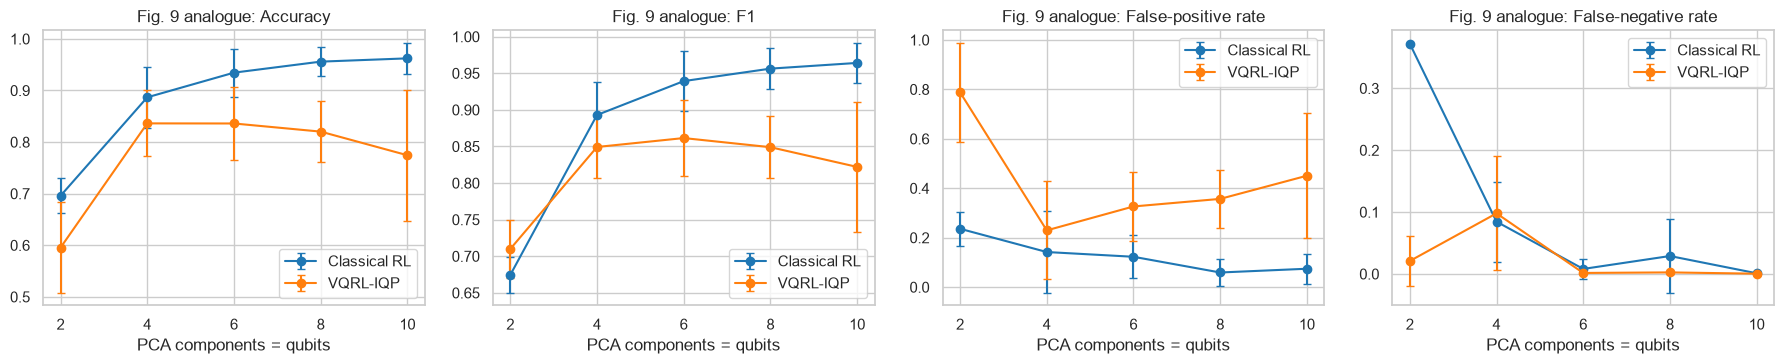

Table 4 analogue (5 runs each):


,Metric,Classical RL (PCA 6),VQRL-IQP (PCA 8),t-test p,Mann-Whitney p
0,Accuracy,0.9346 +/- 0.0463,0.8203 +/- 0.0585,0.0098,0.0159
1,Precision,0.8937 +/- 0.0672,0.7408 +/- 0.0640,0.0062,0.0159
2,Recall,0.9919 +/- 0.0163,0.9975 +/- 0.0020,0.4866,0.4802
3,F1,0.9393 +/- 0.0411,0.8490 +/- 0.0423,0.0090,0.0317
4,FPR,0.1228 +/- 0.0862,0.3570 +/- 0.1165,0.0079,0.0159
5,FNR,0.0081 +/- 0.0163,0.0025 +/- 0.0020,0.4866,0.4802
6,Training time (s),9.0738 +/- 1.1586,115.2169 +/- 1.8758,NaN,NaN


paper Table 4: acc 0.9198+/-0.0783 vs 0.7820+/-0.0143 | recall 0.8470 vs 0.8084 | FPR 0.0070 vs 0.2445 | training time 63 s vs 4615 s
Table 5 analogue (ROC-AUC):


,run (seed),Classical AUC,VQRL-IQP AUC
0,42,0.8725,0.9724
1,43,0.9943,0.9711
2,44,0.9858,0.9926
3,45,0.9968,0.9886
4,46,0.9992,0.9928
5,mean,0.9697,0.9835
6,std,0.0546,0.0109


paper Table 5: mean AUC classical 0.9910 (std 0.0087), VQRL-IQP 0.8740 (std 0.0300)


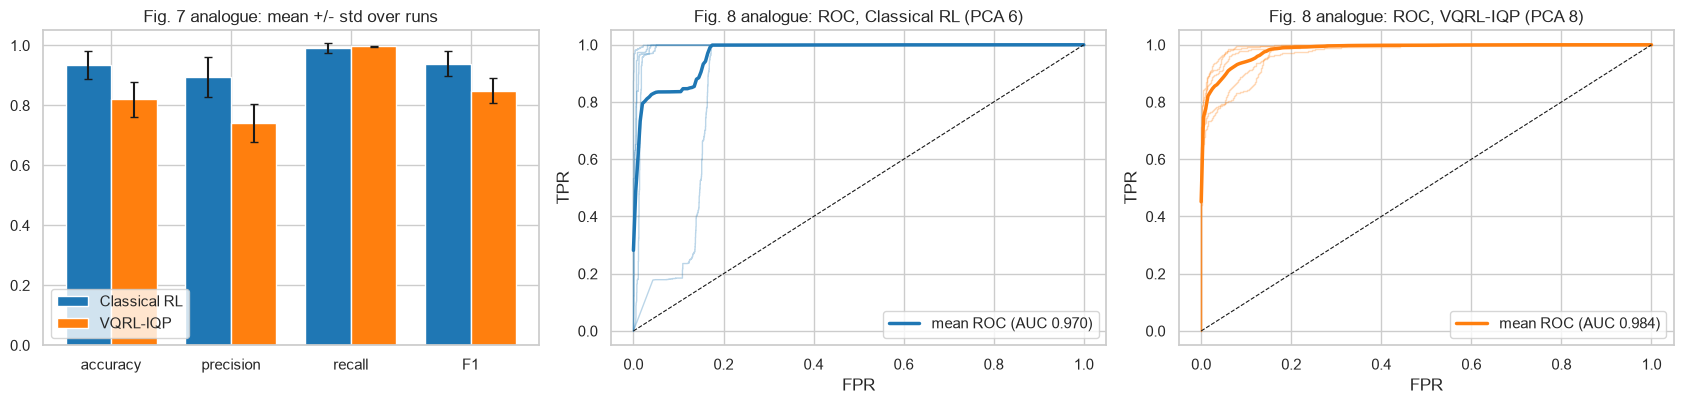

In [15]:
fig, ax = plt.subplots(1, 4, figsize=(18, 3.8))
for a, mt, ttl in zip(ax, ["acc", "f1", "fpr", "fnr"], ["Accuracy", "F1", "False-positive rate", "False-negative rate"]):
    for kind, c in (("classical", "tab:blue"), ("iqp", "tab:orange")):
        d = sweep[sweep.kind == kind].groupby("n")[mt].agg(["mean", "std"]).fillna(0)
        a.errorbar(d.index, d["mean"], d["std"], marker="o", capsize=3, c=c, label=LABEL[kind])
    a.set_title(f"Fig. 9 analogue: {ttl}"); a.set_xlabel("PCA components = qubits"); a.set_xticks(PCA_LIST); a.legend()
plt.tight_layout(); plt.show()

# Table 4 / 5 analogue: the best configurations, repeated runs, with significance tests
from scipy import stats
cl = sweep[(sweep.kind == "classical") & (sweep.n == PCA_CLASSICAL_BEST)].sort_values("seed")
qu = sweep[(sweep.kind == "iqp") & (sweep.n == PCA_QUANTUM_BEST)].sort_values("seed")
rows4 = []
for mt, nm in [("acc", "Accuracy"), ("prec", "Precision"), ("rec", "Recall"), ("f1", "F1"), ("fpr", "FPR"), ("fnr", "FNR"), ("time_s", "Training time (s)")]:
    if len(cl) > 1 and len(qu) > 1 and mt != "time_s":
        pt = stats.ttest_ind(cl[mt], qu[mt], equal_var=False).pvalue
        try: pw = stats.mannwhitneyu(cl[mt], qu[mt]).pvalue
        except Exception: pw = float("nan")
    else: pt = pw = float("nan")
    rows4.append({"Metric": nm, f"Classical RL (PCA {PCA_CLASSICAL_BEST})": f"{cl[mt].mean():.4f} +/- {cl[mt].std():.4f}",
                  f"VQRL-IQP (PCA {PCA_QUANTUM_BEST})": f"{qu[mt].mean():.4f} +/- {qu[mt].std():.4f}", "t-test p": round(pt, 4), "Mann-Whitney p": round(pw, 4)})
print(f"Table 4 analogue ({len(cl)} runs each):"); display(pd.DataFrame(rows4))
print("paper Table 4: acc 0.9198+/-0.0783 vs 0.7820+/-0.0143 | recall 0.8470 vs 0.8084 | FPR 0.0070 vs 0.2445 | training time 63 s vs 4615 s")
auc_tab = pd.DataFrame({"run (seed)": list(cl.seed), "Classical AUC": list(cl.auc.round(4)), "VQRL-IQP AUC": list(qu.auc.round(4))})
auc_tab.loc[len(auc_tab)] = ["mean", round(cl.auc.mean(), 4), round(qu.auc.mean(), 4)]
auc_tab.loc[len(auc_tab)] = ["std", round(cl.auc.std(), 4), round(qu.auc.std(), 4)]
print("Table 5 analogue (ROC-AUC):"); display(auc_tab)
print("paper Table 5: mean AUC classical 0.9910 (std 0.0087), VQRL-IQP 0.8740 (std 0.0300)")

fig, ax = plt.subplots(1, 3, figsize=(17, 4.2))
for mt, c, off in (("classical", "tab:blue", 0), ("iqp", "tab:orange", 1)):
    sub = sweep[(sweep.kind == mt) & (sweep.n == (PCA_CLASSICAL_BEST if mt == "classical" else PCA_QUANTUM_BEST))]
    ax[0].bar(np.arange(4) + 0.38 * off, [sub[k].mean() for k in ("acc", "prec", "rec", "f1")], 0.38, yerr=[sub[k].std() if len(sub) > 1 else 0 for k in ("acc", "prec", "rec", "f1")], capsize=3, color=c, label=LABEL[mt])
ax[0].set_xticks(np.arange(4) + 0.19); ax[0].set_xticklabels(["accuracy", "precision", "recall", "F1"]); ax[0].set_ylim(0, 1.05); ax[0].set_title("Fig. 7 analogue: mean +/- std over runs"); ax[0].legend()
for kind, c, a in (("classical", "tab:blue", ax[1]), ("iqp", "tab:orange", ax[2])):
    n_ = PCA_CLASSICAL_BEST if kind == "classical" else PCA_QUANTUM_BEST
    grid = np.linspace(0, 1, 201); tprs = []
    for k in range(N_SEEDS):
        m = RUNS[(kind, n_, SEED + k, tuple(REWARD), EPISODES)]
        f_, t_, _ = roc_curve(y_test, m["p1"]); tprs.append(np.interp(grid, f_, t_)); a.plot(f_, t_, c=c, alpha=0.3, lw=1)
    a.plot(grid, np.mean(tprs, 0), c=c, lw=2.5, label=f"mean ROC (AUC {np.mean([RUNS[(kind, n_, SEED + k, tuple(REWARD), EPISODES)]['auc'] for k in range(N_SEEDS)]):.3f})")
    a.plot([0, 1], [0, 1], "k--", lw=0.8); a.set_title(f"Fig. 8 analogue: ROC, {LABEL[kind]} (PCA {n_})"); a.set_xlabel("FPR"); a.set_ylabel("TPR"); a.legend(loc="lower right")
plt.tight_layout(); plt.show()

## 7. Reward sensitivity (Table 7)

Table 7 sweeps the penalty for a false negative (FN in {-1, -2, -3, -4}) against the penalty for a false positive (FP in {-0.5, -1, -1.5, -2}),
for both agents, and counts how many of the 16 combinations give a policy that is **not degenerate** (a degenerate policy predicts one class for
every flow: all-attack, FPR = 1 and FNR = 0, or all-normal, FPR = 0 and FNR = 1). The paper reports 2 non-degenerate combinations for VQRL-IQP and 6 for
classical RL. The paper does not say which PCA size or how many seeds the sweep used; here every combination is one run at PCA =
`REWARD_PCA` with `SEED`, the true-positive and true-negative rewards stay at +2.

FN -1.0: done (7.8 min elapsed)


FN -2.0: done (16.6 min elapsed)


FN -3.0: done (26.1 min elapsed)


FN -4.0: done (44.7 min elapsed)


Table 7 analogue (PCA 8, one seed per cell):


C-ACC    C-F1   C-FPR   C-FNR   Q-ACC    Q-F1   Q-FPR   Q-FNR
FN   FP                                                                  
-4.0 -2.0  0.9744  0.9750  0.0504  0.0008  0.9200  0.9257  0.1568  0.0032
     -1.5  0.9542  0.9562  0.0904  0.0012  0.8702  0.8843  0.2512  0.0084
     -1.0  0.9554  0.9573  0.0884  0.0008  0.8406  0.8624  0.3180  0.0008
     -0.5  0.9482  0.9507  0.1028  0.0008  0.7490  0.7992  0.5012  0.0008
-3.0 -2.0  0.9388  0.9423  0.1216  0.0008  0.9410  0.9431  0.0968  0.0212
     -1.5  0.9014  0.9102  0.1964  0.0008  0.9074  0.9147  0.1780  0.0072
     -1.0  0.9596  0.9611  0.0800  0.0008  0.8212  0.8450  0.3324  0.0252
     -0.5  0.9468  0.9494  0.1056  0.0008  0.7784  0.8185  0.4424  0.0008
-2.0 -2.0  0.9642  0.9654  0.0704  0.0012  0.9628  0.9628  0.0376  0.0368
     -1.5  0.9542  0.9562  0.0908  0.0008  0.9208  0.9258  0.1464  0.0120
     -1.0  0.8728  0.8871  0.2536  0.0008  0.8868  0.8979  0.2220  0.0044
     -0.5  0.9844  0.9846  0.0296  0.0016  0.7590  0.8050  0.4768  0.0052
-1.0 -2.0  0.9250  0.9191  0.0020  0.1480  0.9022  0.8919  0.0028  0.1928
     -1.5  0.9766  0.9771  0.0456  0.0012  0.9124  0.9061  0.0208  0.1544
     -1.0  0.9580  0.9562  0.0020  0.0820  0.9164  0.9154  0.0716  0.0956
     -0.5  0.9594  0.9609  0.0800  0.0012  0.8040  0.8360  0.3908  0.0012

non-degenerate policies out of 16 reward pairs: classical RL 16, VQRL-IQP 16   (paper: classical 6, VQRL-IQP 2 of 16)


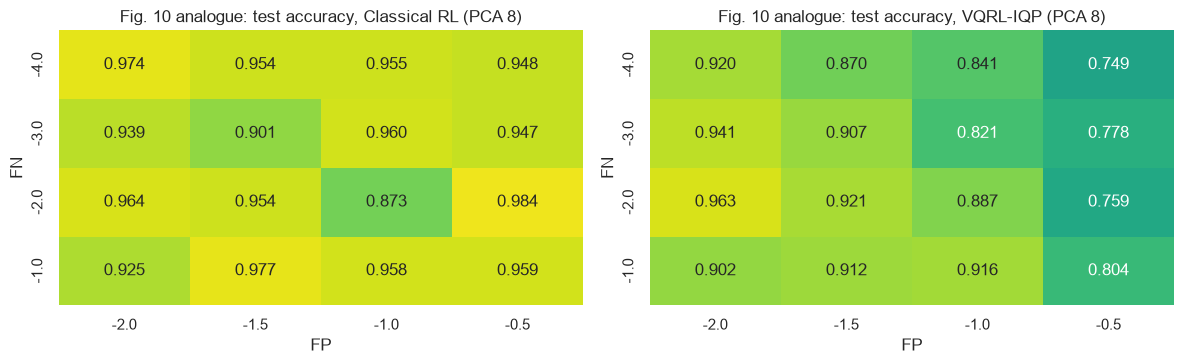

In [16]:
t_rw = time.time(); rw_rows = []
for fn in FN_GRID:
    for fp in FP_GRID:
        rw = (REWARD[0], REWARD[1], fn, fp)
        for kind in ("classical", "iqp"):
            m = run_cached(kind, REWARD_PCA, SEED, rw)
            rw_rows.append(dict(FN=fn, FP=fp, model=kind, **row(m)))
    print(f"FN {fn}: done ({(time.time()-t_rw)/60:.1f} min elapsed)", flush=True)
rwdf = pd.DataFrame(rw_rows)
def degenerate(r): return (r.fpr >= 0.99 and r.fnr <= 0.01) or (r.fpr <= 0.01 and r.fnr >= 0.99)
rwdf["degenerate"] = rwdf.apply(degenerate, axis=1)
wide = rwdf.pivot_table(index=["FN", "FP"], columns="model", values=["acc", "f1", "fpr", "fnr"])
wide.columns = [f"{'C' if m == 'classical' else 'Q'}-{v.upper()}" for v, m in wide.columns]
wide = wide[["C-ACC", "C-F1", "C-FPR", "C-FNR", "Q-ACC", "Q-F1", "Q-FPR", "Q-FNR"]]
print(f"Table 7 analogue (PCA {REWARD_PCA}, one seed per cell):"); display(wide.round(4))
nd = {k: int((~rwdf[rwdf.model == k].degenerate).sum()) for k in ("classical", "iqp")}
print(f"non-degenerate policies out of {len(FN_GRID) * len(FP_GRID)} reward pairs: classical RL {nd['classical']}, VQRL-IQP {nd['iqp']}   (paper: classical 6, VQRL-IQP 2 of 16)")
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
for a, kind in zip(ax, ("classical", "iqp")):
    d = rwdf[rwdf.model == kind].pivot(index="FN", columns="FP", values="acc")
    sns.heatmap(d, annot=True, fmt=".3f", cmap="viridis", vmin=0.4, vmax=1, ax=a, cbar=False); a.set_title(f"Fig. 10 analogue: test accuracy, {LABEL[kind]} (PCA {REWARD_PCA})")
plt.tight_layout(); plt.show()

## 8. Ablation: what does the embedding add? (Figure 11)

The paper shows Figure 11 only qualitatively and says a numerical ablation is "left for future work". Because the whole point of the title is that
performance depends on the *embedding*, the notebook computes it: at PCA = `REWARD_PCA` and the paper's reward, `ABL_SEEDS` seeds each of
(i) VQRL-IQP, (ii) the same hybrid with the authors' `AngleEmbedding` (`RX(x_i)`; the authors' repository contains this variant), (iii) a hybrid in
which the quantum layer is **removed** (`Linear(n,n)` - tanh - `Linear(n,32)` - tanh - `Linear(32,2)`), and (iv) the classical MLP.

Classical RL: done (0.0 min elapsed)


Hybrid without quantum layer (ablation): done (0.9 min elapsed)


VQRL-Angle (ablation): done (12.6 min elapsed)


VQRL-IQP: done (12.6 min elapsed)


,acc,prec,rec,f1,fpr,fnr,auc,time_s
model,,,,,,,,
Classical RL,0.9657 +/- 0.0321,0.9776 +/- 0.0118,0.9539 +/- 0.0771,0.9642 +/- 0.0350,0.0225 +/- 0.0129,0.0461 +/- 0.0771,0.9982 +/- 0.0012,8.9809 +/- 0.4966
Hybrid without quantum layer (ablation),0.9612 +/- 0.0079,0.9466 +/- 0.0227,0.9785 +/- 0.0358,0.9617 +/- 0.0086,0.0561 +/- 0.0262,0.0215 +/- 0.0358,0.9961 +/- 0.0027,18.8123 +/- 2.8539
VQRL-Angle (ablation),0.8907 +/- 0.0560,0.8257 +/- 0.0727,0.9987 +/- 0.0002,0.9028 +/- 0.0444,0.2173 +/- 0.1121,0.0013 +/- 0.0002,0.9830 +/- 0.0144,230.8977 +/- 26.2043
VQRL-IQP,0.8287 +/- 0.0669,0.7506 +/- 0.0739,0.9975 +/- 0.0023,0.8553 +/- 0.0489,0.3400 +/- 0.1319,0.0025 +/- 0.0023,0.9787 +/- 0.0121,116.2047 +/- 0.2450


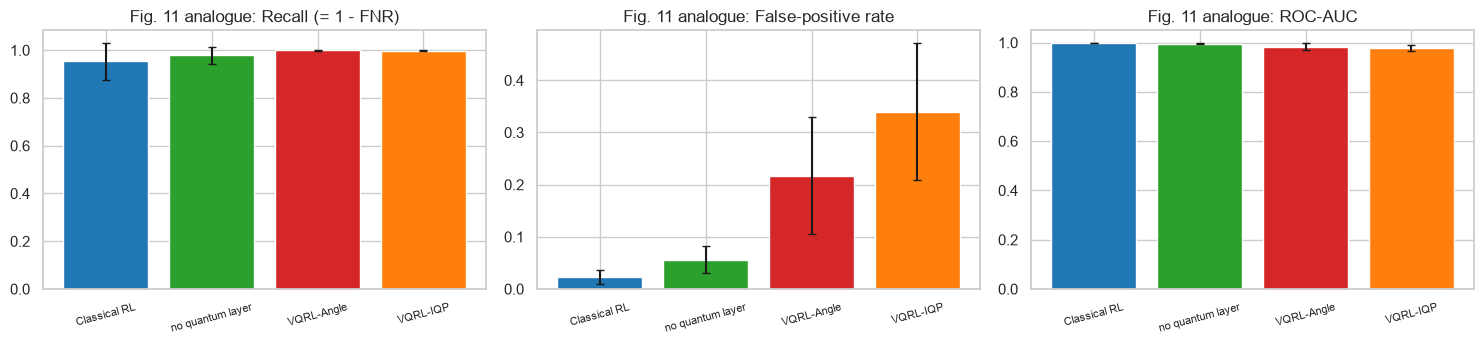

In [17]:
t_ab = time.time(); ab_rows = []
for kind in ("classical", "noquantum", "angle", "iqp"):
    for k in range(ABL_SEEDS):
        m = run_cached(kind, REWARD_PCA, SEED + k)
        ab_rows.append(dict(model=LABEL[kind], seed=SEED + k, **row(m)))
    print(f"{LABEL[kind]}: done ({(time.time()-t_ab)/60:.1f} min elapsed)", flush=True)
abdf = pd.DataFrame(ab_rows)
ab_agg = abdf.groupby("model", sort=False)[["acc", "prec", "rec", "f1", "fpr", "fnr", "auc", "time_s"]].agg(["mean", "std"])
display(pd.DataFrame({m: ab_agg[m]["mean"].map("{:.4f}".format) + " +/- " + ab_agg[m]["std"].fillna(0).map("{:.4f}".format) for m in ["acc", "prec", "rec", "f1", "fpr", "fnr", "auc", "time_s"]}))
fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
for a, mt, ttl in zip(ax, ["rec", "fpr", "auc"], ["Recall (= 1 - FNR)", "False-positive rate", "ROC-AUC"]):
    d = abdf.groupby("model", sort=False)[mt].agg(["mean", "std"]).fillna(0)
    a.bar(range(len(d)), d["mean"], yerr=d["std"], capsize=3, color=["tab:blue", "tab:green", "tab:red", "tab:orange"]); a.set_xticks(range(len(d))); a.set_xticklabels([s.split(" (")[0].replace("Hybrid without quantum layer", "no quantum layer") for s in d.index], rotation=15, fontsize=8)
    a.set_title(f"Fig. 11 analogue: {ttl}")
plt.tight_layout(); plt.show()

## 9. The supervised baselines (Table 8, Figures 12-14)

Table 8 lists five supervised classifiers on the same data: Random Forest, XGBoost, an RBF-SVM, an MLP and a cost-sensitive Random Forest. They
reach 99.1-99.8 % accuracy, far above both reinforcement-learning agents; this is the paper's honest reference point. The paper does not give their
settings, so scikit-learn and XGBoost defaults are used on **all standardised features** (the setting that gives near-perfect accuracy), and the
same models are also trained on the identical 8 PCA scores that the quantum agent sees, which is the fair comparison for the quantum policy.
The cost-sensitive RF weights the attack class four times as much as the benign class (the 2 : 0.5 ratio of the reward).

In [18]:
from xgboost import XGBClassifier
def supervised_models():
    return {"Random Forest": RandomForestClassifier(n_estimators=100, random_state=SEED, n_jobs=2),
            "XGBoost": XGBClassifier(n_estimators=100, random_state=SEED, n_jobs=2, eval_metric="logloss"),
            "SVM (RBF)": SVC(kernel="rbf", random_state=SEED),
            "MLP": MLPClassifier(hidden_layer_sizes=(64, 64), max_iter=200, random_state=SEED),
            "Cost-sensitive RF": RandomForestClassifier(n_estimators=100, class_weight={0: 1, 1: 4}, random_state=SEED, n_jobs=2)}   # CHOICE: weights 1:4
sup_rows, sup_scores, sup_preds = [], {}, {}
for inp, (A_tr, A_te) in {"all 68 features": (Z_tr, Z_te), f"PCA {PCA_QUANTUM_BEST}": (P_tr[:, :PCA_QUANTUM_BEST], P_te[:, :PCA_QUANTUM_BEST])}.items():
    for nm, mdl in supervised_models().items():
        t1 = time.time(); mdl.fit(A_tr, y_train)
        score = mdl.decision_function(A_te) if hasattr(mdl, "decision_function") else mdl.predict_proba(A_te)[:, 1]
        pred = mdl.predict(A_te); tn, fp, fn, tp = confusion_matrix(y_test, pred, labels=[0, 1]).ravel()
        prec = tp / (tp + fp) if tp + fp else 0; rec = tp / (tp + fn)
        sup_rows.append(dict(input=inp, model=nm, acc=100 * (tp + tn) / len(y_test), prec=100 * prec, rec=100 * rec, f1=100 * 2 * prec * rec / (prec + rec),
                             auc=100 * roc_auc_score(y_test, score), fpr=100 * fp / (fp + tn), fnr=100 * fn / (fn + tp), fp=int(fp), fn=int(fn), time_s=time.time() - t1))
        sup_scores[(inp, nm)] = score; sup_preds[(inp, nm)] = pred
sup = pd.DataFrame(sup_rows)
print("Table 8 analogue (percent); test flows: %d benign + %d attack" % tuple(np.bincount(y_test))); display(sup.round(2))
print("paper Table 8 (all features): RF 99.78 | XGBoost 99.74 | SVM-RBF 99.10 | MLP 99.66 | cost-sensitive RF 99.80 (accuracy, %)")

Table 8 analogue (percent); test flows: 2500 benign + 2500 attack


,input,model,acc,prec,rec,f1,auc,fpr,fnr,fp,fn,time_s
0,all 68 features,Random Forest,99.92,100.00,99.84,99.92,100.00,0.00,0.16,0,4,7.61
1,all 68 features,XGBoost,99.98,100.00,99.96,99.98,100.00,0.00,0.04,0,1,3.57
2,all 68 features,SVM (RBF),98.72,97.58,99.92,98.74,99.98,2.48,0.08,62,2,14.28
3,all 68 features,MLP,99.96,100.00,99.92,99.96,100.00,0.00,0.08,0,2,45.60
4,all 68 features,Cost-sensitive RF,99.96,100.00,99.92,99.96,100.00,0.00,0.08,0,2,6.38
5,PCA 8,Random Forest,99.92,100.00,99.84,99.92,100.00,0.00,0.16,0,4,4.89
6,PCA 8,XGBoost,99.94,100.00,99.88,99.94,100.00,0.00,0.12,0,3,1.31
7,PCA 8,SVM (RBF),98.40,97.05,99.84,98.42,99.95,3.04,0.16,76,4,8.45
8,PCA 8,MLP,99.92,99.96,99.88,99.92,100.00,0.04,0.12,1,3,41.74
9,PCA 8,Cost-sensitive RF,99.92,100.00,99.84,99.92,100.00,0.00,0.16,0,4,9.66


paper Table 8 (all features): RF 99.78 | XGBoost 99.74 | SVM-RBF 99.10 | MLP 99.66 | cost-sensitive RF 99.80 (accuracy, %)


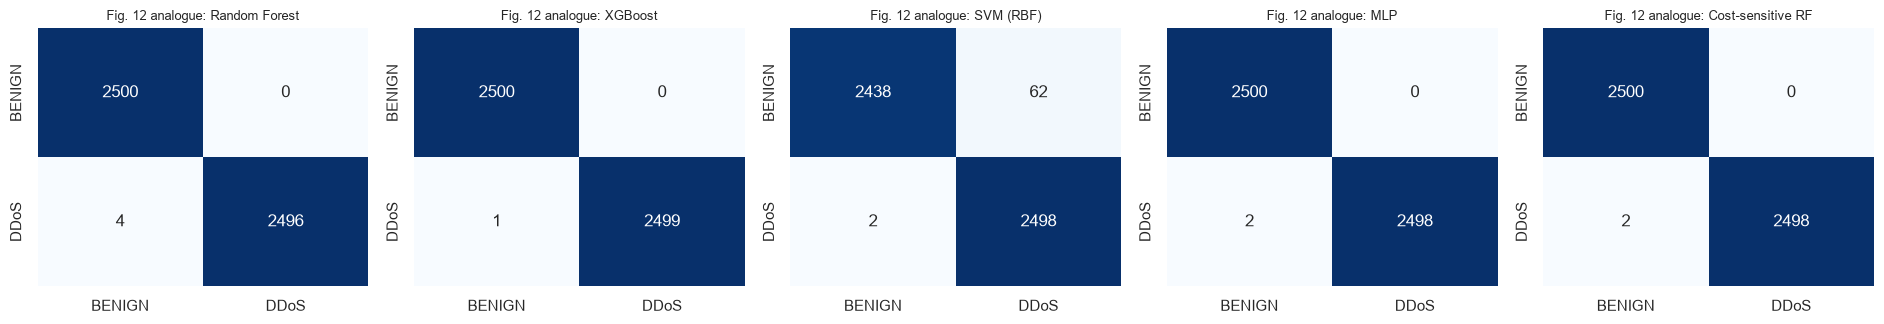

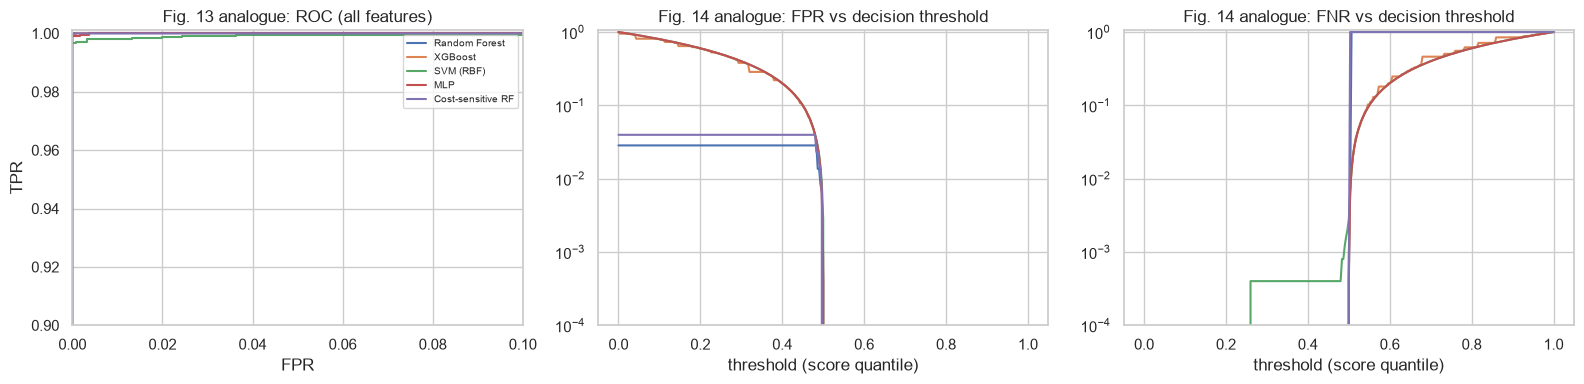

Lowering the threshold of a supervised model drives its FNR toward 0 at the price of FPR, which is the paper's own caveat to the 'lower FNR' claim.


In [19]:
fig, ax = plt.subplots(1, 5, figsize=(19, 3.4))
for a, nm in zip(ax, supervised_models()):
    cm_ = confusion_matrix(y_test, sup_preds[("all 68 features", nm)])
    sns.heatmap(cm_, annot=True, fmt="d", cmap="Blues", cbar=False, ax=a, xticklabels=["BENIGN", "DDoS"], yticklabels=["BENIGN", "DDoS"]); a.set_title(f"Fig. 12 analogue: {nm}", fontsize=9)
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for nm in supervised_models():
    s = sup_scores[("all 68 features", nm)]
    f_, t_, _ = roc_curve(y_test, s); ax[0].plot(f_, t_, label=nm)
    thr = np.quantile(s, np.linspace(0.0, 1.0, 301))
    fpr_t = [((s > t) & (y_test == 0)).sum() / (y_test == 0).sum() for t in thr]; fnr_t = [((s <= t) & (y_test == 1)).sum() / (y_test == 1).sum() for t in thr]
    ax[1].plot(np.linspace(0, 1, 301), fpr_t, label=nm); ax[2].plot(np.linspace(0, 1, 301), fnr_t, label=nm)
ax[0].set_title("Fig. 13 analogue: ROC (all features)"); ax[0].set_xlim(0, 0.1); ax[0].set_ylim(0.9, 1.001); ax[0].set_xlabel("FPR"); ax[0].set_ylabel("TPR"); ax[0].legend(fontsize=7)
ax[1].set_title("Fig. 14 analogue: FPR vs decision threshold"); ax[2].set_title("Fig. 14 analogue: FNR vs decision threshold")
for a in ax[1:]: a.set_xlabel("threshold (score quantile)"); a.set_yscale("log"); a.set_ylim(1e-4, 1.05)
plt.tight_layout(); plt.show()
print("Lowering the threshold of a supervised model drives its FNR toward 0 at the price of FPR, which is the paper's own caveat to the 'lower FNR' claim.")

## 10. The authors' released outputs (cross-check)

The authors' repository (commit `f7b8a00`) also contains result files of their runs: for each PCA size a folder with `test_metrics_classical.csv` and
`test_metrics_hybrid.csv`. Only some folders are present. The cell reads whatever exists at that commit and shows it next to the paper's Table 3. These files
come from the authors' pipeline *with* the leakage described above (SMOTE, scaler and PCA fitted on all data before the split, benign flows oversampled
with replacement), and their test set has about 5,040 flows; they are shown for orientation, not as ground truth.

In [20]:
import requests
rawbase = f"https://raw.githubusercontent.com/raidanis/QRL_IDS/{AUTHORS_COMMIT}/"
rel = [(f"IQP-pca{n_}", f"IQPEmbedding/IQP-pca{n_}") for n_ in (2, 4, 6, 8, 10)] + [(f"Angle-pca{n_}", f"AngleEmbedding/Angle-pca{n_}") for n_ in (2, 4, 6, 8, 10)]
rel_rows = []
for tag, folder in rel:
    for who in ("classical", "hybrid"):
        try:
            r = requests.get(rawbase + f"{folder}/test_metrics_{who}.csv", timeout=30)
            if r.status_code != 200: continue
            d = pd.read_csv(io.StringIO(r.text)).iloc[0]
            rel_rows.append(dict(run=tag, policy=who, acc=d.accuracy, prec=d.precision, rec=d.recall, f1=d.f1, fpr=d.false_positive_rate, fnr=d.false_negative_rate))
        except Exception as e:
            print("could not read", tag, who, type(e).__name__)
released = pd.DataFrame(rel_rows)
if len(released): display(released.round(4))
else: print("no released result files could be fetched (offline?)")
print("paper Table 3 (VQRL-IQP, best single runs): PCA 2 acc 0.6576 | PCA 4 0.8740 | PCA 6 0.9054 | PCA 8 0.9582 | PCA 10 0.7980. The released files do not reproduce this table.")

could not read IQP-pca2 classical ConnectionError
could not read IQP-pca2 hybrid ConnectionError
could not read IQP-pca4 classical ConnectionError
could not read IQP-pca4 hybrid ConnectionError
could not read IQP-pca6 classical ConnectionError
could not read IQP-pca6 hybrid ConnectionError
could not read IQP-pca8 classical ConnectionError
could not read IQP-pca8 hybrid ConnectionError
could not read IQP-pca10 classical ConnectionError
could not read IQP-pca10 hybrid ConnectionError
could not read Angle-pca2 classical ConnectionError
could not read Angle-pca2 hybrid ConnectionError
could not read Angle-pca4 classical ConnectionError


could not read Angle-pca4 hybrid ConnectionError
could not read Angle-pca6 classical ConnectionError
could not read Angle-pca6 hybrid ConnectionError
could not read Angle-pca8 classical ConnectionError
could not read Angle-pca8 hybrid ConnectionError
could not read Angle-pca10 classical ConnectionError


could not read Angle-pca10 hybrid ConnectionError
no released result files could be fetched (offline?)
paper Table 3 (VQRL-IQP, best single runs): PCA 2 acc 0.6576 | PCA 4 0.8740 | PCA 6 0.9054 | PCA 8 0.9582 | PCA 10 0.7980. The released files do not reproduce this table.


## 11. Paper versus this notebook, claim by claim

Verdicts: **reproduced** = within 0.02 (accuracy, precision, recall, F1, FPR, FNR, AUC, explained variance) or within one count / the same direction for
counted or qualitative claims; **not reached** / **exceeded** = outside the tolerance, with the gap; **cannot be checked** = not testable here. The
"best seed" columns pick, as the paper's Tables 2-3 do, the best of our runs on the **test** set (an optimistic selection); the repeated-run claims of
Tables 4-5 are judged on the mean over seeds.

In [21]:
def verdict(ours, paper, tol=0.02):
    gap = ours - paper
    return ("reproduced" if abs(gap) <= tol else ("exceeded" if gap > 0 else "not reached")) + f" ({gap:+.4f})"
def bestrow(kind, n_):
    d = sweep[(sweep.kind == kind) & (sweep.n == n_)]
    return d.loc[d.f1.idxmax()] if len(d) else None
def meanrow(kind, n_):
    d = sweep[(sweep.kind == kind) & (sweep.n == n_)]
    return d.mean(numeric_only=True) if len(d) else None
claims = []
def add(where, claim, paper, ours, verd): claims.append({"where": where, "claim": claim, "paper": paper, "this notebook": ours, "verdict": verd})
f4 = lambda v: f"{v:.4f}"

for n_, pv in {2: 0.3838, 4: 0.5751, 6: 0.6709, 8: 0.7383, 10: 0.7946}.items():
    if n_ in PCA_LIST: add("Table 6", f"cumulative explained variance, PCA {n_}", pv, f4(cumvar[n_ - 1]), verdict(float(cumvar[n_ - 1]), pv))
bc, bq = bestrow("classical", PCA_CLASSICAL_BEST), bestrow("iqp", PCA_QUANTUM_BEST)
for mt, pv in (("acc", 0.9602), ("rec", 0.9275), ("f1", 0.9590)):
    add("Table 2 (best seed)", f"Classical RL PCA {PCA_CLASSICAL_BEST}: {mt}", pv, f4(bc[mt]), verdict(bc[mt], pv))
for mt, pv in (("acc", 0.9582), ("rec", 0.9988), ("f1", 0.9593), ("fpr", 0.0812), ("fnr", 0.0012)):
    add("Table 2/Fig. 6 (best seed)", f"VQRL-IQP PCA {PCA_QUANTUM_BEST}: {mt}", pv, f4(bq[mt]), verdict(bq[mt], pv))
mc, mq = meanrow("classical", PCA_CLASSICAL_BEST), meanrow("iqp", PCA_QUANTUM_BEST)
for who, m_, items in (("Classical RL", mc, (("acc", 0.9198), ("rec", 0.8470), ("fpr", 0.0070), ("auc", 0.9910))),
                       ("VQRL-IQP", mq, (("acc", 0.7820), ("rec", 0.8084), ("fpr", 0.2445), ("auc", 0.8740)))):
    for mt, pv in items:
        add("Tables 4-5 (mean over seeds)", f"{who}: {mt}", pv, f4(m_[mt]), verdict(m_[mt], pv))
add("Table 4", "training-time ratio VQRL-IQP / classical RL", "73x (4615 s / 63 s)", f"{mq['time_s'] / mc['time_s']:.1f}x ({mq['time_s']:.0f} s / {mc['time_s']:.0f} s)",
    "cannot be checked (batched exact simulator vs the authors' step-by-step loop)")
# Table 6 collapse claim
hi_n = [n_ for n_ in PCA_LIST if n_ >= 6]
col_q = int(sweep[(sweep.kind == "iqp") & (sweep.n.isin(hi_n))].collapsed_all_attack.sum()); tot_q = int(((sweep.kind == "iqp") & (sweep.n.isin(hi_n))).sum())
add("Table 6", "VQRL-IQP collapses to all-attack at PCA >= 6 (fixed budget)", "all runs", f"{col_q} of {tot_q} runs collapsed", "reproduced" if col_q >= 0.5 * tot_q else "not reached (no systematic collapse here)")
d2 = sweep[sweep.kind == "classical"].groupby("n").acc.mean()
add("Table 6 / Fig. 9", "classical RL accuracy improves from the smallest PCA size to PCA 8", "monotone up to 8", f"{d2.iloc[0]:.3f} (PCA {d2.index[0]}) -> {d2.get(8, np.nan):.3f} (PCA 8)", "reproduced" if d2.get(8, 0) > d2.iloc[0] else "not reached")
# Table 7
if FAST_MODE:
    add("Table 7", "non-degenerate reward pairs (classical 6 / VQRL-IQP 2 of 16)", "6 / 2", f"{nd['classical']} / {nd['iqp']} of {len(FN_GRID) * len(FP_GRID)}", "cannot be checked (FAST_MODE grid is 4 pairs)")
else:
    add("Table 7", "non-degenerate reward pairs, classical RL", 6, int(nd["classical"]), "reproduced" if abs(nd["classical"] - 6) <= 1 else ("exceeded" if nd["classical"] > 6 else "not reached"))
    add("Table 7", "non-degenerate reward pairs, VQRL-IQP", 2, int(nd["iqp"]), "reproduced" if abs(nd["iqp"] - 2) <= 1 else ("exceeded" if nd["iqp"] > 2 else "not reached"))
    add("Table 7", "VQRL-IQP is more reward-sensitive than classical RL (fewer non-degenerate pairs)", "2 < 6", f"{nd['iqp']} vs {nd['classical']}", "reproduced" if nd["iqp"] < nd["classical"] else "not reached")
# Table 8
for nm, pv in {"Random Forest": 99.78, "XGBoost": 99.74, "SVM (RBF)": 99.10, "MLP": 99.66, "Cost-sensitive RF": 99.80}.items():
    v = float(sup[(sup.input == "all 68 features") & (sup.model == nm)].acc.iloc[0])
    add("Table 8", f"{nm} accuracy (%)", pv, f"{v:.2f}", verdict(v / 100, pv / 100))
# qualitative claims
add("Sections 5.2, 6.3", "VQRL-IQP has lower FNR than classical RL at their best configurations (mean over seeds)", "yes", f"{mq['fnr']:.4f} vs {mc['fnr']:.4f}", "reproduced" if mq["fnr"] < mc["fnr"] else "not reached")
add("Sections 5.2, 6.3", "... at the price of a higher FPR", "yes", f"{mq['fpr']:.4f} vs {mc['fpr']:.4f}", "reproduced" if mq["fpr"] > mc["fpr"] else "not reached")
add("Section 6.5", "classical RL has equal or higher accuracy than VQRL-IQP (mean over seeds)", "yes", f"{mc['acc']:.4f} vs {mq['acc']:.4f}", "reproduced" if mc["acc"] >= mq["acc"] - 0.02 else "not reached")
sv = sup[(sup.input == "all 68 features")].acc.min() / 100
add("Section 6.9", "every supervised baseline beats both RL agents in accuracy", "yes", f"worst supervised {sv:.4f} vs best RL mean {max(mc['acc'], mq['acc']):.4f}", "reproduced" if sv > max(mc["acc"], mq["acc"]) else "not reached")
add("Abstract", "no general quantum advantage in accuracy is claimed", "none claimed", f"VQRL-IQP {mq['acc']:.4f} vs classical RL {mc['acc']:.4f}", "reproduced (no advantage found either)" if mq["acc"] <= mc["acc"] + 0.02 else "exceeded")
cmp_df = pd.DataFrame(claims)
display(cmp_df.style.set_properties(**{"text-align": "left"}).hide(axis="index"))
v = cmp_df.verdict.str.extract(r"^(reproduced|exceeded|not reached|cannot be checked)")[0]
print(v.value_counts().to_string())
print(f"\nTotal wall-clock time of this notebook run: {(time.time() - T_START) / 60:.1f} min (FAST_MODE = {FAST_MODE}).")

where,claim,paper,this notebook,verdict
Table 6,"cumulative explained variance, PCA 2",0.383800,0.3633,not reached (-0.0205)
Table 6,"cumulative explained variance, PCA 4",0.575100,0.5806,reproduced (+0.0055)
Table 6,"cumulative explained variance, PCA 6",0.670900,0.6699,reproduced (-0.0010)
Table 6,"cumulative explained variance, PCA 8",0.738300,0.7410,reproduced (+0.0027)
Table 6,"cumulative explained variance, PCA 10",0.794600,0.7979,reproduced (+0.0033)
Table 2 (best seed),Classical RL PCA 6: acc,0.960200,0.9762,reproduced (+0.0160)
Table 2 (best seed),Classical RL PCA 6: rec,0.927500,0.9992,exceeded (+0.0717)
Table 2 (best seed),Classical RL PCA 6: f1,0.959000,0.9767,reproduced (+0.0177)
Table 2/Fig. 6 (best seed),VQRL-IQP PCA 8: acc,0.958200,0.8924,not reached (-0.0658)
Table 2/Fig. 6 (best seed),VQRL-IQP PCA 8: rec,0.998800,0.9984,reproduced (-0.0004)


0
reproduced           20
exceeded             10
not reached           6
cannot be checked     1

Total wall-clock time of this notebook run: 109.0 min (FAST_MODE = False).


## Reading the paper critically

1. **"Reinforcement learning" here is cost-weighted classification.** Every flow is an independent, immediately rewarded decision; the action does not change
   the next state and there is no delayed reward (the paper says so itself). REINFORCE with this reward is a noisy estimate of the gradient of a
   *cost-weighted* classification loss, with the asymmetry (-2 for a miss against -0.5 for a false alarm) as the only ingredient that supervised learning
   does not already have through class weights. The cost-sensitive Random Forest of Table 8 gets there with FNR 0.20 % and FPR 0.20 % at once.
2. **The quantum part is small and is sandwiched between trainable classical layers.** The circuit has `3nL` = 48 angles at 8 qubits, but the hybrid policy has
   several hundred classical parameters around it, including a trainable `Linear(n,n)` that decides which angles the circuit sees. The ablation of
   section 8 (a hybrid with the quantum layer removed) is the fair test of what the circuit adds; the paper's Figure 11 shows it only qualitatively.
   The title promises an embedding-dependent study, but only IQP is evaluated in the paper; AngleEmbedding appears in the authors' repository only.
3. **Which numbers to believe.** Table 2 and Table 3 are *best single runs* with per-configuration tuning that is not described and, apparently, selected on the test split.
   Tables 4 and 6 are the honest ones: mean accuracy 0.78 and mean ROC-AUC 0.87 for VQRL-IQP, and an all-attack collapse for PCA >= 6 under a fixed budget. A policy
   that flags everything has recall 1.000 and FNR 0; "near-zero FNR" is only meaningful next to the FPR, and the paper's own reward sweep shows the quantum agent
   is non-degenerate in just 2 of 16 reward settings.
4. **The data are easy.** Friday-afternoon DDoS against benign traffic is separated almost perfectly by every supervised model (99.1-99.8 %). Any shortfall of an RL agent on
   this task is a statement about the optimiser (a policy gradient with 200 noisy samples per update), not about quantum feature spaces.
5. **Comparisons of cost and accuracy are not like for like.** The 73x training-time ratio compares a step-by-step PennyLane loop with a PyTorch MLP; here the same circuit is
   simulated in a batched way and the cost per episode drops by orders of magnitude. All results are exact statevector simulations: no shot noise, no hardware noise,
   no barren-plateau test at larger sizes.
6. **Reproducibility problems in the released code.** The repository's pipeline fits SMOTE, the scaler and the PCA on all data before splitting and samples benign flows with
   replacement (duplicate rows can fall on both sides of the split); the text of the paper describes the leak-free order instead. The text says 45,000 flows, the test
   set of the figures and the code use 25,000. The `StronglyEntanglingLayers` template has a CNOT ring whose range grows with the layer index, not the "full all-to-all topology" of Table 1.
7. **Heavy tails.** After standardisation some DDoS flows have z-scores above 100 (the first principal components inherit this); the authors' code does not clip them, relying on
   `tanh` to compress the angles. The scatter plots above show how concentrated the bulk of the data is compared with the outliers.

## Exercises

1. **Is the circuit doing anything?** Compare `HybridPolicy(n, 2, "none")` with `"iqp"` over 10 seeds at PCA 4 and PCA 8 and test the difference in AUC with a paired test. What does the answer say about the paper's Figure 11?
2. **Symmetric rewards.** Train VQRL-IQP and classical RL with the reward `(2, 2, -1, -1)` (no asymmetry). Does the quantum agent still show a lower FNR and a higher FPR than classical RL? How much of the paper's "error profile" is reward shaping?
3. **A supervised head.** Replace REINFORCE by cross-entropy training of the *same* hybrid network (a class-weighted loss with weights 4 : 1 for attack : normal). Compare recall, FPR and AUC with the RL version at equal numbers of gradient steps.
4. **Depth and repetitions.** The IQP embedding can be repeated (`n_repeats=2`) and `N_LAYERS` can be raised. Extend `CircuitSim._embed` (or switch on `USE_PENNYLANE_LAYER`) and test whether the collapse at PCA >= 6 disappears.
5. **Hold-out the attack tool.** The DDoS file contains one attack tool. Train on Friday-afternoon DDoS and test on the Wednesday DoS file (same Hugging Face repository); which of the agents and supervised baselines survive the distribution shift?